# CS1090A / AC209A — Milestone 2: Data Wrangling and Project Redefinition

**Canvas project group #: 7** · **Project #12 — Forecasting Stock Volatility on the S&P 500: Can Machine Learning Beat HAR?**

**Group members:** Debbie · YiTong Li · Cathy · Anthony · Nic

| § | Section | Owner | Status in this notebook |
|---|---|---|---|
| 0 | Setup | YiTong | code |
| 1 | Getting the data | **Debbie** (collected the data) — loading code by YiTong | code ✔ |
| 2 | Understanding the data (rows, columns, types, summary stats, **timing check**) | **YiTong** | code ✔ |
| 3 | Cleaning & preprocessing of the stock panel (universe, target draft, missingness, unusual values, scale, imbalance, leakage) | **YiTong** | code ✔ |
| 4 | Time-series EDA (distribution, persistence, stationarity, auto-ARIMA, per-stock HAR, clustering, cross-section, seasonality) | **YiTong** | code ✔ |
| 5 | Target & volatility features (final target, HAR/EWMA/range features, baseline set-up) | **Cathy** | *to do* (text) |
| 6 | Market data integration & leakage audit (Goyal–Welch macro, FF5, merged table, walk-forward splits) | **Anthony** | *to do* (text) |
| 7 | Sector mapping, data dictionary, revised proposal & slides | **Nic** | *to do* (text) |
| 8 | Revised project question (draft for the group) | all | text |

> **One-line summary.** One row of our final table is *one large U.S. stock in one month*. From everything known at the end of month *t−1*, we predict the log of that stock's realized volatility in month *t*. The questions are whether pooled ML models (ridge/lasso/elastic net, gradient-boosted trees) beat the per-stock HAR benchmark, which features drive any gain, and whether the gain survives in stress periods.

> **Why monthly, not weekly (change from the original proposal).** The data the group has is the Gu–Kelly–Xiu (GKX) monthly firm-characteristics panel, plus the monthly Goyal–Welch macro data and Fama–French factors. None of them has daily high/low prices, so the weekly Garman–Klass target cannot be built from them. GKX does include `retvol`, the standard deviation of a stock's daily returns within a month, which is a monthly realized volatility. We therefore move the forecast horizon from one week to one month, with HAR lags of 1, 3 and 12 months instead of 1, 5 and 22 days.

## 0. Setup

In [1]:
import os, time, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from statsmodels.tsa.stattools import adfuller, kpss, acf, pacf
from statsmodels.stats.diagnostic import acorr_ljungbox
from statsmodels.tsa.arima.model import ARIMA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler
warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', 60); pd.set_option('display.width', 200)
pd.set_option('display.float_format', lambda v: f'{v:,.4g}')
plt.rcParams.update({'figure.dpi': 110, 'axes.titlesize': 13, 'axes.labelsize': 12,
                     'xtick.labelsize': 10, 'ytick.labelsize': 10, 'legend.fontsize': 10})
DATA = os.path.join('..', 'Data')          # raw data folder (Debbie)
OUT  = 'data_clean'                         # cleaned tables written by this notebook
os.makedirs(OUT, exist_ok=True)
RNG = np.random.default_rng(1090)
# Walk-forward split fixed IN ADVANCE (target months). EDA that informs model choices uses <= VAL_END only.
TRAIN_END, VAL_END = pd.Timestamp('2010-12-31'), pd.Timestamp('2015-12-31')
STRESS_EPISODES = [('1973-11','1974-12','Oil shock'), ('1987-10','1987-12','1987 crash'),
                   ('2000-09','2002-10','Dot-com bust'), ('2008-09','2009-06','GFC'),
                   ('2020-02','2020-06','COVID')]

## 1. Getting the data  *(owner: Debbie — data collected; loading code: YiTong)*

| File (in `../Data`) | Source | Frequency / span | Used for |
|---|---|---|---|
| `datashare.csv` (raw, 3.8 GB) → `datashare_small.parquet` (same rows, float32) | Gu, Kelly & Xiu (2020) firm characteristics, https://dachxiu.chicagobooth.edu/download/datashare.zip | monthly, 1957-01 → 2021-12, all CRSP stocks | stock-level features **and** the volatility target (`retvol`) |
| `datashare_sample.parquet` | 700 random stocks from the same file | same | quick prototyping only |
| `Data2024.xlsx - Monthly.csv` | Goyal & Welch predictor data (2024 update), https://sites.google.com/view/agoyal145 | monthly, 1871 → 2024-12 | market-wide state (S&P variance `svar`, T-bill, spreads, valuation ratios) |
| `F-F_Research_Data_5_Factors_2x3.csv` | Kenneth French Data Library, https://mba.tuck.dartmouth.edu/pages/faculty/ken.french/data_library.html | monthly, 1963-07 → 2026-09 | market/size/value/profitability/investment factor returns |

The raw files are already on disk (downloaded by Debbie; the original zips are in `../Data/Archive`). The cell below **reports their size** and loads them.

In [2]:
def folder_sizes(root):
    rows = []
    for dp, _, fs in os.walk(root):
        for f in fs:
            p = os.path.join(dp, f); rows.append((os.path.relpath(p, root), os.path.getsize(p) / 2**20))
    return pd.DataFrame(rows, columns=['file', 'MB']).sort_values('MB', ascending=False)
sizes = folder_sizes(DATA)
display(sizes)
print(f"Total size of ../Data: {sizes.MB.sum()/1024:.2f} GB  "
      f"(raw, uncompressed GKX csv alone: {sizes.loc[sizes.file=='datashare.csv','MB'].iloc[0]/1024:.2f} GB)")

,file,MB
1,datashare.csv,"3,658"
6,Archive\datashare.zip,"1,484"
3,datashare_small.parquet,562.9
2,datashare_sample.parquet,14.4
0,Data2024.xlsx - Monthly.csv,0.4978
4,F-F_Research_Data_5_Factors_2x3.csv,0.04899
7,Archive\F-F_Research_Data_5_Factors_2x3_CSV.zip,0.01142
5,readme.txt,0.001159


Total size of ../Data: 5.59 GB  (raw, uncompressed GKX csv alone: 3.57 GB)


In [3]:
t0 = time.time()
gkx = pd.read_parquet(os.path.join(DATA, 'datashare_small.parquet'))
gkx['date'] = pd.to_datetime(gkx['date'])
# the parquet must contain every row of the raw csv (count newlines without parsing 3.8 GB)
with open(os.path.join(DATA, 'datashare.csv'), 'rb') as fh:
    n_csv = sum(chunk.count(b'\n') for chunk in iter(lambda: fh.read(1 << 24), b'')) - 1
print(f'GKX parquet: {gkx.shape[0]:,} rows x {gkx.shape[1]} cols; raw csv rows = {n_csv:,}; '
      f'match = {n_csv == len(gkx)}; in-memory {gkx.memory_usage().sum()/2**30:.2f} GB; {time.time()-t0:.0f}s')

gw = pd.read_csv(os.path.join(DATA, 'Data2024.xlsx - Monthly.csv'))
gw['ym'] = pd.PeriodIndex(gw['yyyymm'].astype(str), freq='M')
gw = gw.set_index('ym').drop(columns='yyyymm').apply(pd.to_numeric, errors='coerce')
print(f'Goyal-Welch: {gw.shape[0]:,} months x {gw.shape[1]} cols, {gw.index.min()} -> {gw.index.max()}')

def read_ff_monthly(path):
    rows = []
    for line in open(path, encoding='latin-1'):
        parts = [p.strip() for p in line.split(',')]
        if 'Annual' in line: break                      # monthly block ends where the annual block begins
        if len(parts) == 7 and parts[0].isdigit() and len(parts[0]) == 6:
            rows.append(parts)
    ff = pd.DataFrame(rows, columns=['yyyymm', 'Mkt-RF', 'SMB', 'HML', 'RMW', 'CMA', 'RF'])
    ff.index = pd.PeriodIndex(ff.pop('yyyymm'), freq='M')
    return ff.astype(float) / 100                        # percent -> decimal
ff = read_ff_monthly(os.path.join(DATA, 'F-F_Research_Data_5_Factors_2x3.csv'))
print(f'Fama-French 5: {ff.shape[0]:,} months x {ff.shape[1]} cols, {ff.index.min()} -> {ff.index.max()}')

GKX parquet: 4,117,300 rows x 97 cols; raw csv rows = 4,117,300; match = True; in-memory 1.50 GB; 3s
Goyal-Welch: 1,848 months x 56 cols, 1871-01 -> 2024-12
Fama-French 5: 759 months x 6 cols, 1963-07 -> 2026-09


## 2. Understanding the data  *(owner: YiTong)*

### 2.1 What one row is
* **GKX panel:** one row = **one stock (`permno`, CRSP's permanent ID) at one month-end (`date`)**. Each row has 94 firm characteristics plus the 2-digit SIC industry code `sic2`.
* **Goyal–Welch:** one row = one month of market-wide variables.
* **Fama–French:** one row = one month of five factor returns plus the risk-free rate.

The key fact for leakage is *which month* each value in a GKX row describes. The GKX readme says characteristics have already been lagged, so that a row dated *t* can be used to predict the return of month *t*. Section 2.4 checks this against outside data.

**The three identifier columns of the GKX file** (every other column is a characteristic, defined in the dictionary below):

| Column | Plain meaning | Technical meaning | Example |
|---|---|---|---|
| `permno` | The stock's "ID card number". It never changes, even if the company changes its name or ticker. | CRSP *PERMNO*, an integer that permanently identifies a security in the CRSP database (Center for Research in Security Prices). Our join and grouping key for "the same stock over time". | `10107` = Microsoft |
| `date` | The month the row belongs to. | Last **trading** day of the calendar month (e.g. 1957-03-29), parsed from `DATE` (YYYYMMDD). Because it is the last trading day and not the 31st/30th, we key months on the *calendar month*, not the exact day (see §3.1). | `2020-03-31` |
| `sic2` | Which industry the company is in. | First two digits of the Standard Industrial Classification code. Stored as a float, but **categorical**: 73 is not "more" than 28. | `73` = business services / software |

#### Glossary of terms used throughout this notebook
*Each term is defined in plain words first, then technically.*

* **Stock-month**: one stock observed in one month, i.e. one row of the GKX panel. *Technically:* a (`permno`, month) pair; the panel has 4.1 M of them.
* **Panel data**: many series (stocks) observed over many periods (months) in one long table. *Technically:* long format, indexed by (`permno`, `date`); not i.i.d., because rows of the same stock and of the same month are correlated.
* **Cross-section / cross-sectional**: "all stocks in the same month". A cross-sectional median is the median over all stocks in one month. *Technically:* `groupby('date')` operations.
* **Volatility**: how much a price jumps around. A stock that moves ±3% a day is more volatile than one that moves ±0.5%. *Technically:* the standard deviation of returns; **realized volatility** is the standard deviation measured from the returns that actually happened in a period (here: daily returns within one month = GKX `retvol`). **Realized variance (RV)** is its square.
* **Annualized volatility**: daily volatility rescaled to a yearly number that investors quote (e.g. "20% a year"). *Technically:* daily std × √252 (252 trading days per year).
* **Log volatility** (`lrv`, target `y`): the natural log of `retvol`. Logs turn "×2" moves into "+0.69" moves, so a crash month no longer dwarfs every other month. *Technically:* `np.log(retvol)`; a typical large stock has `retvol` ≈ 0.018 (1.8% a day), so log ≈ −4.0.
* **Target / response (`y`)**: the number we try to forecast: the log realized volatility of a stock in month *t* (built in §3.2).
* **Feature / predictor**: any input the model may use to make the forecast, known *before* the month being forecast.
* **HAR (Heterogeneous AutoRegressive) model**: "next month's volatility ≈ a weighted mix of last month's, the last quarter's and the last year's volatility". *Technically:* OLS of $y_t$ on `har_1`, `har_3`, `har_12` (Corsi 2009), the standard volatility benchmark; defined precisely in §3.2.
* **Universe**: the set of stocks we study in a given month. Ours = the 500 largest stocks by market value that month (§3.3), a stand-in for the S&P 500.
* **Leakage (information leakage)**: accidentally letting the model see information from the future (or from the answer itself) at training time. It makes a model look great in testing and fail in real use.
* **Walk-forward split / embargo**: train on the past, validate on the next block of time, test on the block after; never shuffle time. An *embargo* is an unused gap between blocks so that no training row overlaps a test row.
* **Stress month**: a month in which the whole market was turbulent; defined in §3.7 as S&P 500 realized variance (`svar`) above the 90th percentile of the training period.

In [4]:
# data dictionary for the 94 GKX characteristics (Green, Hand & Zhang 2017 / GKX 2020 Table A.6)
# freq = how often the underlying data updates: M monthly (CRSP prices), Q quarterly / A annual (Compustat)
D = [
('absacc','Absolute accruals','accounting','A'),('acc','Working capital accruals','accounting','A'),
('aeavol','Abnormal earnings announcement volume','trading','Q'),('age','Years since first Compustat coverage','firm','A'),
('agr','Asset growth','accounting','A'),('baspread','Bid-ask spread','trading','M'),('beta','Market beta (3y weekly)','risk','M'),
('betasq','Beta squared','risk','M'),('bm','Book-to-market','valuation','A'),('bm_ia','Industry-adjusted book-to-market','valuation','A'),
('cash','Cash holdings / assets','accounting','Q'),('cashdebt','Cash flow to debt','accounting','A'),('cashpr','Cash productivity','accounting','A'),
('cfp','Cash flow to price','valuation','A'),('cfp_ia','Industry-adjusted cash flow to price','valuation','A'),
('chatoia','Industry-adj. change in asset turnover','accounting','A'),('chcsho','Change in shares outstanding','accounting','A'),
('chempia','Industry-adj. change in employees','accounting','A'),('chinv','Change in inventory','accounting','A'),
('chmom','Change in 6-month momentum','momentum','M'),('chpmia','Industry-adj. change in profit margin','accounting','A'),
('chtx','Change in tax expense','accounting','Q'),('cinvest','Corporate investment','accounting','Q'),
('convind','Convertible debt indicator (0/1)','accounting','A'),('currat','Current ratio','accounting','A'),
('depr','Depreciation / PP&E','accounting','A'),('divi','Dividend initiation (0/1)','accounting','A'),('divo','Dividend omission (0/1)','accounting','A'),
('dolvol','log dollar trading volume','trading','M'),('dy','Dividend yield','valuation','A'),('ear','Earnings announcement return','trading','Q'),
('egr','Growth in common equity','accounting','A'),('ep','Earnings to price','valuation','A'),('gma','Gross profitability','accounting','A'),
('grcapx','Growth in capital expenditures','accounting','A'),('grltnoa','Growth in long-term net operating assets','accounting','A'),
('herf','Industry sales concentration (Herfindahl)','firm','A'),('hire','Employee growth rate','accounting','A'),
('idiovol','Idiosyncratic return volatility (3y weekly)','risk','M'),('ill','Amihud illiquidity','trading','M'),
('indmom','Industry momentum','momentum','M'),('invest','Capex and inventory investment','accounting','A'),('lev','Leverage','accounting','A'),
('lgr','Growth in long-term debt','accounting','A'),('maxret','Maximum daily return in the month','risk','M'),
('mom12m','12-month momentum','momentum','M'),('mom1m','1-month momentum (last month return)','momentum','M'),
('mom36m','36-month momentum','momentum','M'),('mom6m','6-month momentum','momentum','M'),('ms','Financial statement score (Mohanram, 0-8)','accounting','Q'),
('mvel1','Market equity (size, $000), lagged','firm','M'),('mve_ia','Industry-adjusted size','firm','A'),
('nincr','Number of consecutive earnings increases (0-8)','accounting','Q'),('operprof','Operating profitability','accounting','A'),
('orgcap','Organizational capital','accounting','A'),('pchcapx_ia','Industry-adj. % change in capex','accounting','A'),
('pchcurrat','% change in current ratio','accounting','A'),('pchdepr','% change in depreciation','accounting','A'),
('pchgm_pchsale','% chg gross margin - % chg sales','accounting','A'),('pchquick','% change in quick ratio','accounting','A'),
('pchsale_pchinvt','% chg sales - % chg inventory','accounting','A'),('pchsale_pchrect','% chg sales - % chg receivables','accounting','A'),
('pchsale_pchxsga','% chg sales - % chg SG&A','accounting','A'),('pchsaleinv','% change in sales-to-inventory','accounting','A'),
('pctacc','Percent accruals','accounting','A'),('pricedelay','Price delay (speed of reaction to market news)','trading','M'),
('ps','Piotroski F-score (0-9)','accounting','A'),('quick','Quick ratio','accounting','A'),('rd','R&D increase (0/1)','accounting','A'),
('rd_mve','R&D to market cap','valuation','A'),('rd_sale','R&D to sales','accounting','A'),('realestate','Real estate holdings','accounting','A'),
('retvol','Std. dev. of daily returns in the month (realized volatility)','risk','M'),('roaq','Return on assets','accounting','Q'),
('roavol','Earnings volatility','accounting','Q'),('roeq','Return on equity','accounting','Q'),('roic','Return on invested capital','accounting','A'),
('rsup','Revenue surprise','accounting','Q'),('salecash','Sales to cash','accounting','A'),('saleinv','Sales to inventory','accounting','A'),
('salerec','Sales to receivables','accounting','A'),('secured','Secured debt','accounting','A'),('securedind','Secured debt indicator (0/1)','accounting','A'),
('sgr','Sales growth','accounting','A'),('sin','Sin stock: alcohol/tobacco/gaming (0/1)','firm','A'),('sp','Sales to price','valuation','A'),
('std_dolvol','Volatility of dollar volume','trading','M'),('std_turn','Volatility of share turnover','trading','M'),
('stdacc','Accrual volatility','accounting','Q'),('stdcf','Cash flow volatility','accounting','Q'),('tang','Tangibility / debt capacity','accounting','A'),
('tb','Tax income to book income','accounting','A'),('turn','Share turnover','trading','M'),('zerotrade','Zero-trading days','trading','M')]
dd = pd.DataFrame(D, columns=['column', 'meaning', 'group', 'freq']).set_index('column')
CHARS = dd.index.tolist()
assert set(CHARS) == set(gkx.columns) - {'permno', 'date', 'sic2'}, 'dictionary does not match the file'
dd['dtype'] = gkx[CHARS].dtypes.astype(str)
dd['n_unique'] = [gkx[c].nunique() for c in CHARS]
BINARY = dd.index[dd.n_unique <= 2].tolist()
print('Shape:', gkx.shape, '| dtypes:', gkx.dtypes.value_counts().to_dict())
print('Counts by group:', dd.group.value_counts().to_dict(), '| by update frequency:', dd.freq.value_counts().to_dict())
print('Binary (0/1) columns:', BINARY)

# ---- sample values for every column ----------------------------------------------------------
# integer-valued columns (dummies, scores, codes): list the distinct values with their share of rows;
# continuous columns: show the 1st / 25th / 50th / 75th / 99th percentiles as representative values.
def is_integer_valued(s):
    v = s.dropna()
    return len(v) > 0 and bool(np.all(np.mod(v.values, 1) == 0))
def sample_values(s, max_levels=12):
    v = s.dropna()
    if is_integer_valued(s) and v.nunique() <= max_levels:
        vc = v.value_counts(normalize=True).sort_index()
        return 'levels: ' + ', '.join(f'{k:g} ({100*p:.0f}%)' for k, p in vc.items())
    if is_integer_valued(s):
        return f'integer, {v.nunique()} levels, e.g. ' + ', '.join(f'{x:g}' for x in np.sort(v.unique())[:8]) + ', ...'
    qs = v.quantile([.01, .25, .5, .75, .99]).values
    return 'p1/p25/p50/p75/p99: ' + ' / '.join(f'{x:.3g}' for x in qs)
dd['value_type'] = ['binary 0/1' if c in BINARY else ('integer' if is_integer_valued(gkx[c]) else 'continuous') for c in CHARS]
dd['sample_values'] = [sample_values(gkx[c]) for c in CHARS]
dd['missing_%'] = (100 * gkx[CHARS].isna().mean()).round(2)

# identifiers + industry code, so the saved dictionary covers EVERY column of the file
ids = pd.DataFrame({
    'meaning': ['CRSP permanent security ID (integer key, e.g. 10107 = Microsoft)',
                'Last trading day of the month (row t = information known at end of month t-1, see 2.4)',
                'First 2 digits of the SIC industry code (categorical, e.g. 73 = business services)'],
    'group': ['identifier', 'identifier', 'industry (categorical)'], 'freq': ['-', 'M', 'M'],
    'dtype': [str(gkx[c].dtype) for c in ['permno', 'date', 'sic2']],
    'n_unique': [gkx[c].nunique() for c in ['permno', 'date', 'sic2']],
    'value_type': ['integer ID', 'date', 'categorical code'],
    'sample_values': [', '.join(map(str, gkx.permno.drop_duplicates().sample(5, random_state=0).sort_values())) + ', ...',
                      f"{gkx.date.min():%Y-%m-%d} ... {gkx.date.max():%Y-%m-%d}",
                      'most common: ' + ', '.join(f'{int(k)} ({100*p:.0f}%)' for k, p in gkx.sic2.value_counts(normalize=True).head(6).items())],
    'missing_%': [100 * gkx[c].isna().mean().round(4) for c in ['permno', 'date', 'sic2']]},
    index=pd.Index(['permno', 'date', 'sic2'], name='column'))
data_dict = pd.concat([ids, dd])

DOCS = 'Data Definition and Summary Statistics'          # tables too wide to read in the notebook output
os.makedirs(DOCS, exist_ok=True)
data_dict.to_csv(os.path.join(DOCS, 'gkx_data_dictionary.csv'), encoding='utf-8-sig')
print(f'saved full dictionary ({len(data_dict)} columns) -> {DOCS}/gkx_data_dictionary.csv')
with pd.option_context('display.max_rows', 200, 'display.max_colwidth', 90):
    display(data_dict)

Shape: (4117300, 97) | dtypes: {dtype('float32'): 95, dtype('int32'): 1, dtype('<M8[s]'): 1}
Counts by group: {'accounting': 60, 'trading': 10, 'valuation': 8, 'momentum': 6, 'firm': 5, 'risk': 5} | by update frequency: {'A': 61, 'M': 20, 'Q': 13}
Binary (0/1) columns: ['convind', 'divi', 'divo', 'rd', 'securedind', 'sin']


saved full dictionary (97 columns) -> Data Definition and Summary Statistics/gkx_data_dictionary.csv


,meaning,group,freq,dtype,n_unique,value_type,sample_values,missing_%
column,,,,,,,,
permno,"CRSP permanent security ID (integer key, e.g. 10107 = Microsoft)",identifier,-,int32,32793,integer ID,"13929, 21886, 66457, 83146, 93249, ...",0
date,"Last trading day of the month (row t = information known at end of month t-1, see 2.4)",identifier,M,datetime64[s],780,date,1957-01-31 ... 2021-12-31,0
sic2,"First 2 digits of the SIC industry code (categorical, e.g. 73 = business services)",industry (categorical),M,float32,74,categorical code,"most common: 67 (11%), 60 (8%), 73 (7%), 28 (7%), 36 (6%), 35 (5%)",7.3
absacc,Absolute accruals,accounting,A,float32,217702,continuous,p1/p25/p50/p75/p99: 0.000966 / 0.0291 / 0.0616 / 0.114 / 0.528,37.39
acc,Working capital accruals,accounting,A,float32,216120,continuous,p1/p25/p50/p75/p99: -0.484 / -0.0762 / -0.0229 / 0.0402 / 0.289,37.39
aeavol,Abnormal earnings announcement volume,trading,Q,float32,784756,continuous,p1/p25/p50/p75/p99: -0.946 / -0.243 / 0.279 / 1.12 / 9.98,39.95
age,Years since first Compustat coverage,firm,A,float32,59,integer,"integer, 59 levels, e.g. 1, 2, 3, 4, 5, 6, 7, 8, ...",24.94
agr,Asset growth,accounting,A,float32,238140,continuous,p1/p25/p50/p75/p99: -2.08 / -0.199 / -0.0725 / 0.0183 / 0.473,30.83
baspread,Bid-ask spread,trading,M,float32,3759895,continuous,p1/p25/p50/p75/p99: 0.0051 / 0.0191 / 0.0325 / 0.0583 / 0.385,0.02


**Data types.** `permno` is an integer ID (identifier, not a feature). `date` is a month-end date. All 94 characteristics are `float32`:
* six are 0/1 dummies (`convind, divi, divo, rd, securedind, sin`);
* four are integer-valued: three small scores (`ps` 0–9, `ms` 0–8, `nincr` 0–8) and `age` (whole years);
* the rest are continuous.

`sic2` is stored as a float but is really **categorical**: we will one-hot encode it or map it to sectors, never treat it as a number.

**How to read the dictionary columns.**
* `meaning`: what the characteristic measures.
* `group`: broad family (accounting, valuation, trading, risk, momentum, firm).
* `freq`: how often the underlying data are refreshed. **M** = monthly from stock prices; **Q** = quarterly and **A** = annual from company financial statements (Compustat). An annual item keeps the same value for 12 rows in a row.
* `value_type` and `sample_values`:
  * For **binary and integer** columns, the actual levels and the share of rows at each level. Example: `ps` is the Piotroski score, an integer from 0 to 9.
  * For **continuous** columns, five representative values: the 1st, 25th, 50th, 75th and 99th percentiles.

**Files saved.** The full tables are too wide to read in the notebook, so they are also written to `MS2/Data Definition and Summary Statistics/`:
* `gkx_data_dictionary.csv`: every GKX column with its meaning, group, frequency, dtype, number of distinct values, value type, sample values and % missing.
* `gkx_summary_statistics.csv`: count, missing %, mean, std, min, 1%, median, 99% and max for every numeric column.
* `goyal_welch_dictionary_and_stats.csv` and `fama_french5_dictionary_and_stats.csv`: the same for the two market-level files.

### 2.2 Summary statistics (mean, min, max, …) of every numerical column

In [5]:
summ = gkx[CHARS + ['sic2']].describe(percentiles=[.01, .5, .99]).T
summ['missing_%'] = 100 * gkx[CHARS + ['sic2']].isna().mean()
summ = summ[['count', 'missing_%', 'mean', 'std', 'min', '1%', '50%', '99%', 'max']]
summ.insert(0, 'meaning', data_dict['meaning'].reindex(summ.index))
summ.to_csv(os.path.join(DOCS, 'gkx_summary_statistics.csv'), encoding='utf-8-sig')
print(f'saved -> {DOCS}/gkx_summary_statistics.csv ({len(summ)} columns)')
with pd.option_context('display.max_rows', 200, 'display.max_colwidth', 40):
    display(summ)

saved -> Data Definition and Summary Statistics/gkx_summary_statistics.csv (95 columns)


,meaning,count,missing_%,mean,std,min,1%,50%,99%,max
absacc,Absolute accruals,2.578e+06,37.39,0.08989,0.09886,0,0.0009657,0.06158,0.5275,1.024
acc,Working capital accruals,2.578e+06,37.39,-0.02461,0.1261,-1.016,-0.4843,-0.02289,0.289,0.5699
aeavol,Abnormal earnings announcement volume,2.472e+06,39.95,0.8135,1.958,-1,-0.9462,0.2785,9.977,20.91
age,Years since first Compustat coverage,3.09e+06,24.94,11.95,10.85,1,1,8,48,59
agr,Asset growth,2.848e+06,30.83,-0.1531,0.415,-5.636,-2.079,-0.07254,0.4726,0.7014
baspread,Bid-ask spread,4.117e+06,0.01569,0.05283,0.07008,-0.4295,0.005104,0.0325,0.3848,0.9818
beta,Market beta (3y weekly),3.717e+06,9.729,1.018,0.647,-0.7996,-0.09873,0.9488,2.896,3.887
betasq,Beta squared,3.717e+06,9.729,1.459,1.727,0,0.0005869,0.904,8.416,15.11
bm,Book-to-market,3.043e+06,26.1,1.379,5.212,-4.753,-0.6106,0.6414,22.99,153.7
bm_ia,Industry-adjusted book-to-market,3.043e+06,26.1,-1.692,7.772,-130.9,-26.29,-0.6689,18.15,137.3


#### Goyal–Welch monthly macro data (`Data2024.xlsx - Monthly.csv`)

**Plain version.** Each row is **one calendar month** (column `yyyymm`, e.g. 202003 = March 2020). It describes the stock market *as a whole* and the economy: where the S&P 500 stood, how much it paid in dividends and earned, interest rates, how turbulent the market was, and so on. Each value applies to every stock in that month. We use it to tell the model whether the market as a whole is calm or nervous.

**Technical version.** Amit Goyal's 2024 update of the Welch & Goyal (2008) and Goyal, Welch & Zafirov (2024) equity-premium predictor file: 1871-01 → 2024-12, 57 columns. Rates and returns are decimals per month, except bond yields, which are annual decimals.
* `d/p` = d12/price: for 1871-01, 0.26 / 4.44 = 0.0586, matching the file.
* Several columns are **empty** in this release (`eqis, cay, i/k, pce, govik, skew, crdstd, accrul, cfacc, gpce, gip, house`). They are quarterly or annual series that are not filled in the monthly sheet, and we drop them.
* The newer variables are named after their source papers, as cited in GWZ 2024. Check the paper's appendix before relying on the exact construction of any of them.

| Column | Meaning (plain → technical) |
|---|---|
| `price` | Level of the S&P 500 index at month end (index points) |
| `d12` | Dividends paid by S&P 500 firms over the last 12 months (index points) |
| `e12` | Earnings of S&P 500 firms over the last 12 months (index points) |
| `ret` / `retx` | S&P 500 return in the month, with / without dividends (CRSP value-weighted) |
| `AAA` / `BAA` | Yield on Moody's top-rated (Aaa) / lower-investment-grade (Baa) corporate bonds (annual) |
| `lty` / `ltr` | Long-term U.S. government bond yield / return |
| `corpr` | Long-term corporate bond return |
| `tbl` | 3-month Treasury-bill rate (annual) |
| `Rfree` | Risk-free return for the month (T-bill) |
| `d/p`, `d/y` | Dividend-price ratio (d12/price); dividend yield (d12/last month's price) |
| `e/p`, `d/e` | Earnings-price ratio (e12/price); payout ratio (d12/e12) |
| `b/m` | Book-to-market ratio of the Dow Jones Industrial Average |
| `tms` | Term spread = `lty` − `tbl` (long minus short rates) |
| `dfy` | Default yield spread = `BAA` − `AAA` (credit risk premium) |
| `dfr` | Default return spread = `corpr` − `ltr` |
| `infl` | CPI inflation (monthly) |
| `ntis` | Net equity expansion: net share issuance by NYSE firms relative to market value |
| **`svar`** | **Stock variance: sum of squared *daily* S&P 500 returns in the month = market realized variance. Our main market-turbulence variable.** |
| `csp` | Cross-sectional beta premium (Polk–Thompson–Vuolteenaho), ends 2002 |
| `vp`, `vrp` | Variance (risk) premium = implied minus realized variance (Bollerslev–Tauchen–Zhou), 1990+ |
| `impvar`, `rsvix` | Implied variance from option prices (VIX²-type), and Martin's SVIX, 1996+ |
| `lzrt` | Log of the number of zero daily returns (market illiquidity) |
| `ogap` | Output gap (economy above/below trend) |
| `wtexas` | Change in West Texas Intermediate oil price |
| `sntm` | Investor sentiment index |
| `ndrbl` | New orders of durable goods |
| `skvw`, `tail` | Average stock skewness (value-weighted); tail-risk measure |
| `fbm` | Cross-sectional book-to-market factor |
| `dtoy`, `dtoat` | Dow index relative to its 52-week high / all-time high |
| `ygap` | Yield gap: equity earnings yield vs. bond yield |
| `rdsp` | Dispersion of stock returns across firms |
| `tchi` | Technical-indicator index |
| `avgcor` | Average pairwise correlation between stocks |
| `shtint` | Aggregate short interest |
| `disag` | Analyst disagreement |

#### Fama–French 5 factors (`F-F_Research_Data_5_Factors_2x3.csv`)

**Plain version.** Each row is **one calendar month**, 1963-07 → 2026-09. It gives six numbers, each the return in that month of an imaginary "bet" portfolio. Example: "small companies minus big companies" was −0.48% in July 1963, so small firms lagged big firms by about half a percent that month.

**Technical version.** Monthly returns from Kenneth French's library. The file gives them in percent; the loader divides by 100. Each factor except `RF` is a long-short portfolio built from 2×3 sorts of NYSE/AMEX/NASDAQ stocks:

| Column | Meaning |
|---|---|
| `Mkt-RF` | Value-weighted U.S. market return minus the 1-month T-bill rate: the market's excess return |
| `SMB` | Small Minus Big: return of small-cap stocks minus large-cap stocks (size) |
| `HML` | High Minus Low: return of high book-to-market ("value") minus low ("growth") stocks |
| `RMW` | Robust Minus Weak: return of high-profitability minus low-profitability firms |
| `CMA` | Conservative Minus Aggressive: return of low-investment minus high-investment firms |
| `RF` | 1-month Treasury-bill return (the risk-free rate) |

In [6]:
GW_DESC = {'price': 'S&P 500 index level', 'd12': '12-month S&P 500 dividends', 'e12': '12-month S&P 500 earnings',
           'ret': 'S&P 500 return incl. dividends', 'retx': 'S&P 500 return excl. dividends', 'AAA': 'Aaa corporate bond yield',
           'BAA': 'Baa corporate bond yield', 'lty': 'long-term govt bond yield', 'ltr': 'long-term govt bond return',
           'corpr': 'long-term corporate bond return', 'tbl': '3-month T-bill rate', 'Rfree': 'risk-free return',
           'd/p': 'dividend-price ratio', 'd/y': 'dividend yield', 'e/p': 'earnings-price ratio', 'd/e': 'payout ratio',
           'b/m': 'DJIA book-to-market', 'tms': 'term spread lty-tbl', 'dfy': 'default yield spread BAA-AAA',
           'dfr': 'default return spread corpr-ltr', 'infl': 'CPI inflation', 'ntis': 'net equity expansion',
           'svar': 'S&P 500 realized variance (sum of squared daily returns)', 'csp': 'cross-sectional beta premium',
           'vp': 'variance premium', 'vrp': 'variance risk premium', 'impvar': 'implied variance', 'rsvix': 'SVIX (Martin)',
           'lzrt': 'log # zero daily returns', 'ogap': 'output gap', 'wtexas': 'WTI oil price change', 'sntm': 'investor sentiment',
           'ndrbl': 'new orders, durable goods', 'skvw': 'avg stock skewness (value-weighted)', 'tail': 'tail risk',
           'fbm': 'cross-sectional book-to-market factor', 'dtoy': 'Dow / 52-week high', 'dtoat': 'Dow / all-time high',
           'ygap': 'yield gap', 'rdsp': 'return dispersion', 'tchi': 'technical-indicator index', 'avgcor': 'average stock correlation',
           'shtint': 'aggregate short interest', 'disag': 'analyst disagreement'}
gw_tab = gw.describe().T[['count', 'mean', 'min', 'max']]
gw_tab.insert(0, 'meaning', pd.Series(GW_DESC).reindex(gw_tab.index).fillna('(empty in this release)'))
gw_tab['first month'] = [str(gw[c].first_valid_index()) for c in gw_tab.index]
gw_tab['last month'] = [str(gw[c].last_valid_index()) for c in gw_tab.index]
gw_tab.to_csv(os.path.join(DOCS, 'goyal_welch_dictionary_and_stats.csv'), encoding='utf-8-sig')
EMPTY_GW = gw_tab.index[gw_tab['count'] == 0].tolist()
print('Goyal-Welch: one row = one calendar month; empty columns (dropped):', EMPTY_GW)
with pd.option_context('display.max_rows', 100): display(gw_tab.drop(EMPTY_GW))

FF_DESC = {'Mkt-RF': 'market excess return', 'SMB': 'small minus big (size)', 'HML': 'high minus low book-to-market (value)',
           'RMW': 'robust minus weak profitability', 'CMA': 'conservative minus aggressive investment', 'RF': '1-month T-bill return'}
ff_tab = ff.describe().T[['count', 'mean', 'std', 'min', 'max']]
ff_tab.insert(0, 'meaning', pd.Series(FF_DESC))
ff_tab.to_csv(os.path.join(DOCS, 'fama_french5_dictionary_and_stats.csv'), encoding='utf-8-sig')
print('Fama-French 5: one row = one calendar month, values = decimal monthly returns. First rows:'); display(ff.head(3)); display(ff_tab)

Goyal-Welch: one row = one calendar month; empty columns (dropped): ['eqis', 'cay', 'i/k', 'pce', 'govik', 'skew', 'crdstd', 'accrul', 'cfacc', 'gpce', 'gip', 'house']


,meaning,count,mean,min,max,first month,last month
price,S&P 500 index level,"1,848",417.4,2.73,"6,032",1871-01,2024-12
d12,12-month S&P 500 dividends,"1,848",8.105,0.18,74.83,1871-01,2024-12
e12,12-month S&P 500 earnings,"1,848",19.3,0.16,210.2,1871-01,2024-12
ret,S&P 500 return incl. dividends,"1,188",0.009627,-0.2875,0.4143,1926-01,2024-12
retx,S&P 500 return excl. dividends,"1,188",0.006558,-0.2915,0.4123,1926-01,2024-12
AAA,Aaa corporate bond yield,"1,272",0.05636,0.0214,0.1549,1919-01,2024-12
BAA,Baa corporate bond yield,"1,272",0.06802,0.0294,0.1718,1919-01,2024-12
lty,long-term govt bond yield,"1,272",0.04908,0.0062,0.1482,1919-01,2024-12
ltr,long-term govt bond return,"1,188",0.004575,-0.1124,0.1523,1926-01,2024-12
corpr,long-term corporate bond return,"1,188",0.004965,-0.0949,0.156,1926-01,2024-12


Fama-French 5: one row = one calendar month, values = decimal monthly returns. First rows:


,Mkt-RF,SMB,HML,RMW,CMA,RF
yyyymm,,,,,,
1963-07,-0.0039,-0.0048,-0.0084,0.0064,-0.0115,0.0027
1963-08,0.0508,-0.008,0.0172,0.004,-0.0038,0.0025
1963-09,-0.0157,-0.0043,-0.0002,-0.0078,0.0015,0.0027


,meaning,count,mean,std,min,max
Mkt-RF,market excess return,759,0.005996,0.04455,-0.2319,0.161
SMB,small minus big (size),759,0.001801,0.03023,-0.1553,0.1854
HML,high minus low book-to-market (value),759,0.002915,0.02969,-0.1383,0.1286
RMW,robust minus weak profitability,759,0.002468,0.02289,-0.1893,0.1304
CMA,conservative minus aggressive investment,759,0.002446,0.02072,-0.0706,0.09
RF,1-month T-bill return,759,0.003627,0.0026,0,0.0135


### 2.3 Coverage over time

* **Coverage** here means how many stocks the GKX file has data for in each month. Coverage grows as more companies list and as CRSP adds exchanges: NASDAQ firms enter at the end of 1972. Because rows are lagged one month (§2.4), the jump appears in the row dated 1973-01, where the count goes from about 2,700 to 5,600.
  *Technically:* `gkx.groupby('date').size()`, the number of `permno` rows per month.
* **Universe size** is the number of stocks we *keep* for modeling each month. We keep 500, the largest by market value, as a proxy for the S&P 500 (§3.3).
  The red dashed line shows that every month has far more than 500 stocks available, so the top-500 universe is always full.

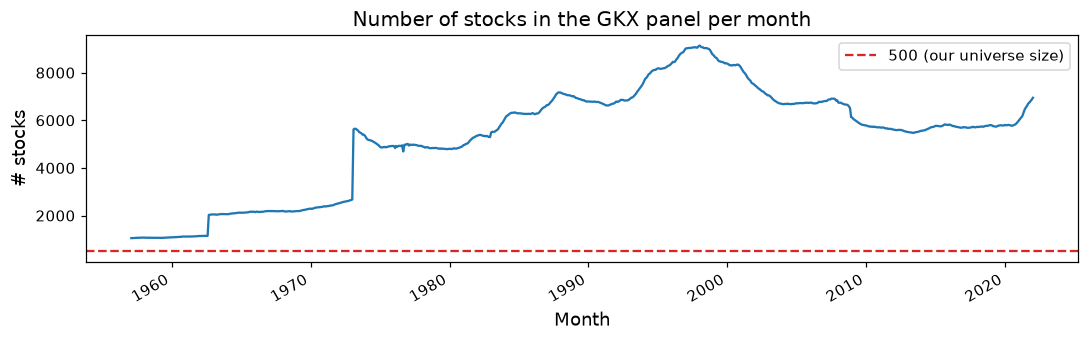

32,793 distinct stocks; 780 months; stocks per month: min 1,053, median 5,728, max 9,140


In [7]:
per_month = gkx.groupby('date').size()
fig, ax = plt.subplots(figsize=(10, 3.2))
per_month.plot(ax=ax, color='C0'); ax.axhline(500, ls='--', color='C3', label='500 (our universe size)')
ax.set(title='Number of stocks in the GKX panel per month', xlabel='Month', ylabel='# stocks'); ax.legend()
plt.tight_layout(); plt.show()
print(f'{gkx.permno.nunique():,} distinct stocks; {per_month.size} months; stocks per month: '
      f'min {per_month.min():,}, median {per_month.median():,.0f}, max {per_month.max():,}')

### 2.4 Timing check: which month does a row's information describe?

This check decides whether our target leaks. If `retvol` in the row dated *t* were the volatility **of month t**, then using the same row's other columns to predict it would mix in information from inside the month we are forecasting.

**Test.** We compare cross-sectional medians of two GKX columns with outside market data at different shifts:
* `mom1m` (last month's return) against the Fama–French market return;
* `retvol` (daily-return volatility) against the Goyal–Welch S&P 500 variance `svar` (sum of squared daily index returns in the month).

**The four variables used in this check:**

| Variable | File → column | Plain meaning | Technical meaning |
|---|---|---|---|
| `retvol` | GKX `datashare_small.parquet` (same as `datashare.csv`) → column `retvol` | How jumpy one stock was during a month. A value of 0.02 means the price typically moved about 2% per day. | Standard deviation of the stock's **daily** returns within one month (CRSP daily file). This is the stock's monthly realized volatility, and its log becomes our target. |
| `mom1m` | GKX → column `mom1m` | How much the stock went up or down over one month. | The stock's 1-month return ("short-term reversal" characteristic). |
| `svar` | Goyal–Welch `Data2024.xlsx - Monthly.csv` → column `svar` | How turbulent the **whole market** (S&P 500) was during a month. | Sum of squared daily S&P 500 returns in the month: the realized variance of the index. |
| `Mkt-RF` | Fama–French `F-F_Research_Data_5_Factors_2x3.csv` → column `Mkt-RF` | How much the whole market went up or down in a month, above the safe T-bill rate. | Value-weighted CRSP market return minus the 1-month T-bill return. |

**Why this pairing works.**
* *Plain:* if the GKX row labelled March really contains February's numbers, then the typical stock's `mom1m` in the March row should move with February's market return, not March's. The same holds for volatility.
* *Technical:* each month we take the **median across all stocks** of `mom1m` (and of `retvol`). That gives one number per month, which removes stock-specific noise and leaves the market-wide component. We then correlate this monthly series with the outside series shifted by −1, 0 and +1 months. The shift with the highest correlation tells us which month the row describes.

In [8]:
g = gkx.assign(ym=gkx.date.dt.to_period('M')).groupby('ym').agg(mom1m=('mom1m', 'median'), retvol=('retvol', 'median'))
chk = g.join(ff['Mkt-RF']).join(gw['svar'])
res = []
for k, lab in [(-1, 'month t-1'), (0, 'month t'), (1, 'month t+1')]:
    res.append({'outside data from': lab,
                'corr(median mom1m in row t, market return)': chk.mom1m.corr(chk['Mkt-RF'].shift(-k)),
                'corr(log median retvol in row t, log svar)': np.log(chk.retvol).corr(np.log(chk.svar.shift(-k)))})
timing = pd.DataFrame(res).set_index('outside data from'); display(timing)

,"corr(median mom1m in row t, market return)","corr(log median retvol in row t, log svar)"
outside data from,,
month t-1,0.8839,0.7039
month t,0.05868,0.5324
month t+1,-0.05198,0.4556


**Result.** `mom1m` in row *t* matches the market return of **month t−1** (correlation ≈ 0.88) and is unrelated to month *t* (≈ 0.06). `retvol` in row *t* tracks the S&P variance of **month t−1** most closely.

So **a row dated t holds information known at the end of month t−1.** This gives a clean, leak-free design:

> **features = row *t* of a stock;  target = `log(retvol)` from row *t+1* of the same stock**, which is the realized volatility of month *t*.

The feature row is fully known before month *t* starts, so no future information enters.

## 3. Cleaning & preprocessing of the stock panel  *(owner: YiTong)*

We work in this order:
1. Check the panel's integrity.
2. Build the target and HAR lags **on the full panel** (so a stock's history before it entered the top 500 still counts).
3. Restrict to the investable universe.
4. Go through the MS2 checklist: missing data, unusual values, scale, class imbalance, leakage.

Cathy (§5) will finalize the target and HAR features. The versions below are drafts that the EDA needs.

### 3.1 Integrity

Recall that `permno` is the permanent stock ID and `date` is the last trading day of the month (§2.1). Two checks:

1. **No duplicates.** Each (`permno`, month) pair should appear only once.
2. **Gaps.** We find months that are missing in the middle of a stock's history.

**What `m` and `gap` are, and why we compute them this way.**

*Plain version.* Think of numbering every month since year 0 in a row: Jan 2020 is month 24,241, Feb 2020 is 24,242, and so on. For one stock, we subtract each row's number from the row before it.
* If the answer is **1**, the two rows are back-to-back months, as they should be.
* If it is **3**, two months are missing in between: that is a **gap**.

We need this because everything we build looks back or forward in time: "last month's volatility", "the average over the last 12 months", "next month's volatility" (the target). These are only correct if the rows really are consecutive months.

*Technical version.*
* `m = year*12 + month` maps each date to an integer month index. Consecutive calendar months differ by exactly 1, **including across a year boundary**: Dec 2019 = 2019·12+12 = 24,240 and Jan 2020 = 24,241.
* We cannot use raw date differences instead, because `date` is the last *trading* day. Months are 28–31 days long and the last trading day moves around (e.g. 2020-02-28 → 2020-03-31 is 32 days), so "30 days" cannot tell consecutive months from a gap.
* `gkx.groupby('permno')['m'].diff()` takes that difference **within each stock** (rows are sorted by `permno`, `date`), so it never compares two different stocks.
* `gap` is NaN for a stock's first row, 1 for a normal step, and > 1 when months are missing.

**Why gaps hurt the analysis and the models (negative effects).**
1. **Wrong lags.** Without the check, `shift(1)` would call the row from 6 months ago "last month". That would put wrong numbers into the HAR features and blur the persistence we measure.
2. **Wrong target.** `shift(-1)` would pair features with a volatility that is *not* next month's. That is a mislabeled response: the forecast horizon would silently change from 1 month to several.
3. **Lost rows.** Respecting gaps means a row right after a gap has no `har_3`/`har_12` for 3 or 12 months, and a row right before a gap has no target. We lose those rows, or must impute them.
4. **Possible selection bias.** Gaps are often not random: trading halts, exchange moves and data outages happen more for distressed or small firms. Dropping those rows can make the sample look calmer than reality. The cell below measures how large this is.

So all lags and the target are built **within gap-free segments**: `seg` in §3.2 starts a new segment at every gap.

In [9]:
gkx = gkx.sort_values(['permno', 'date']).reset_index(drop=True)
n_dup = gkx.duplicated(['permno', 'date']).sum()
dates_per_month = gkx.groupby(gkx.date.dt.to_period('M')).date.nunique().max()
gkx['m'] = gkx.date.dt.year * 12 + gkx.date.dt.month                     # integer month index (consecutive months differ by 1)
gap = gkx.groupby('permno')['m'].diff()                                  # months since this stock's previous row (NaN = first row)
print(f'duplicate (permno, date) rows: {n_dup}; max distinct dates per calendar month: {dates_per_month} '
      f'(DATE is the last TRADING day of the month, so we key on the calendar month)')
print(f'rows whose previous row for that stock is NOT the previous month (gaps): {(gap > 1).sum():,} '
      f'({100*(gap > 1).mean():.2f}%)')

duplicate (permno, date) rows: 0; max distinct dates per calendar month: 1 (DATE is the last TRADING day of the month, so we key on the calendar month)
rows whose previous row for that stock is NOT the previous month (gaps): 5,665 (0.14%)


In [10]:
# How big is the gap problem?
g_len = (gap[gap > 1] - 1).astype(int)                                   # number of missing months in each gap
stocks_with_gap = gkx.loc[gap > 1, 'permno'].nunique()
print(f'stocks with at least one gap: {stocks_with_gap:,} of {gkx.permno.nunique():,} '
      f'({100*stocks_with_gap/gkx.permno.nunique():.1f}%)')
print('length of gaps (missing months):'); display(g_len.value_counts().sort_index().head(6).rename('# gaps').to_frame()
        .rename_axis('missing months').T.assign(**{'>6': int((g_len > 6).sum())}))
# a concrete example: one stock's rows around its first gap
ex_pm = gkx.loc[gap > 1, 'permno'].iloc[0]
ex_i = gkx.index[(gkx.permno == ex_pm) & (gap > 1)][0]
ex = gkx.loc[ex_i - 2: ex_i + 1, ['permno', 'date', 'm', 'retvol']].assign(gap=gap.loc[ex_i - 2: ex_i + 1])
print(f'example (permno {ex_pm}): the jump in m shows the missing months'); display(ex)
# is volatility different right before a gap? (selection-bias check)
before_gap = gkx.groupby('permno')['m'].shift(-1).sub(gkx['m']).gt(1)
print(f"median retvol in the month before a gap: {gkx.loc[before_gap, 'retvol'].median():.4f} "
      f"vs all other rows: {gkx.loc[~before_gap, 'retvol'].median():.4f}")

stocks with at least one gap: 4,227 of 32,793 (12.9%)
length of gaps (missing months):


missing months,1,2,3,4,5,6,>6
# gaps,2830,587,246,181,118,115,1588


example (permno 10007): the jump in m shows the missing months


,permno,date,m,retvol,gap
1255,10007,1987-10-30,23854,0.02672,1
1256,10007,1987-11-30,23855,0.06096,1
1257,10007,1989-03-31,23871,0.1012,16
1258,10007,1989-04-28,23872,0.09308,1


median retvol in the month before a gap: 0.0302 vs all other rows: 0.0232

**What the gap check shows.**

*Plain version.*
* About 1 stock in 8 has at least one hole in its history. In the example above, permno 10007 jumps from November 1987 to March 1989, so 15 months are missing.
* Stocks are noticeably **more volatile just before a hole**: a median daily volatility of 3.0% against 2.3% for all other rows. Holes therefore tend to hit the shakier stocks.

*Technical version.*
* Gaps affect 0.14% of rows but 12.9% of `permno`s. Most are a single missing month, with a long tail of gaps over 6 months (often re-listings).
* Because pre-gap rows have about 30% higher median `retvol`, dropping them would bias the sample slightly toward calm stock-months.
* Inside the top-500 universe this matters much less: large stocks rarely have gaps (see the "why is the target missing" table in §3.4).
* Our handling:
  1. build lags only inside gap-free segments;
  2. lose the target only for the single row right before a gap;
  3. let the size filter, not the gap, decide who is in the sample.

### 3.2 Draft target and HAR lags (built on the full panel, respecting gaps)

The realized variance of month *j* is $RV_j = \text{retvol}_j^2$. With row *t* holding month *t−1*:

* target: $y_t = \log \text{retvol}$ of month *t* (taken from row *t+1*; it is kept only if row *t+1* is exactly the next month);
* `har_1`  $= \log \text{retvol}$ of month *t−1* (row *t*);
* `har_3`  $= \tfrac12 \log \big(\tfrac13\sum_{j=t-3}^{t-1} RV_j\big)$, i.e. the log volatility of the average variance over the last 3 months;
* `har_12` is the same over the last 12 months.

Windows never cross a gap in a stock's history. A `retvol` below $10^{-4}$ means a daily std under 0.01%, about 0.16% a year, which is impossible for a traded large stock: it signals a stale price or no trading. Such values are set to missing **before** taking logs (see §3.5).

In [11]:
STALE = 1e-4                                                          # daily std < 0.01% (~0.16%/yr) = stale price
rv = gkx['retvol'].where(gkx['retvol'] >= STALE)                      # 0 / ~0 -> NaN (see 3.5)
gkx.loc[gkx['baspread'] < 0, 'baspread'] = np.nan                     # impossible negative spread (see 3.5)
gkx['lrv'] = np.log(rv)
nxt_m = gkx.groupby('permno')['m'].shift(-1)
gkx['has_next'] = nxt_m == gkx['m'] + 1
gkx['y'] = gkx.groupby('permno')['lrv'].shift(-1).where(gkx['has_next'])
seg = (gap.fillna(99) > 1).cumsum()                                   # new segment after any gap
var = rv ** 2
for w in (3, 12):
    gkx[f'har_{w}'] = 0.5 * np.log(var.groupby(seg).rolling(w, min_periods=w).mean().reset_index(level=0, drop=True))
gkx['har_1'] = gkx['lrv']
gkx['target_month'] = gkx['date']                                     # y_t is the volatility OF month t
print(gkx[['y', 'har_1', 'har_3', 'har_12']].describe().T[['count', 'mean', 'min', 'max']])

           count   mean    min    max
y      4.043e+06 -3.756 -9.184 -1.324
har_1  4.076e+06 -3.755 -9.196 -1.324
har_3  3.963e+06 -3.679  -9.13  -1.41
har_12 3.584e+06 -3.632 -8.807 -1.532


**Why are the summary statistics of `y` and `har_1` almost identical? This is expected, not an error.**

*Plain version.* `har_1` is "this stock's volatility last month" and `y` is "this stock's volatility this month". Both are drawn from the same long list of monthly volatilities, just one step apart.

Imagine a stock with five months of volatility: 3, 5, 4, 6, 2.
* The `har_1` column lists the months that come *before* a target month: 3, 5, 4, 6.
* The `y` column lists the months that come *after* one: 5, 4, 6, 2.

The two columns share every value except one at each end. With millions of rows, losing one value at each end changes the mean, min and max almost not at all. The numbers still sit on **different rows**: on any given row, last month and this month usually differ.

*Technical version.*
* By construction, $y_{i,t} = \text{har\_1}_{i,t+1}$ whenever row *t+1* is the next month. Both are $\log \text{retvol}$ of the same month, read from two adjacent rows.
* The marginal distributions of the two columns are therefore the same series shifted by one row. They differ only at:
  * the first observation of each gap-free segment, which has a `har_1` but is no stock's target;
  * the last observation, which is a target but not a lag.
* That is about 1 row per segment out of ~4 M, so the counts differ slightly and the means and extremes coincide. The same holds for any stationary series and its first lag.
* The real test is **row-wise**, done below:
  1. $y_{i,t}$ equals the next row's `har_1` exactly;
  2. the correlation between $y$ and `har_1` *on the same row* is clearly below 1. That correlation is the one-month persistence the models exploit, not a copy of the target.

In [12]:
nxt_har1 = gkx.groupby('permno')['har_1'].shift(-1).where(gkx['has_next'])
both = gkx['y'].notna() & nxt_har1.notna()
print(f"rows where y_t == har_1 of row t+1 (same month's volatility): {np.isclose(gkx.loc[both, 'y'], nxt_har1[both]).mean()*100:.2f}%")
print(f"count: y {gkx.y.notna().sum():,} vs har_1 {gkx.har_1.notna().sum():,} "
      f"(difference = segment end points and stale/missing retvol)")
pair = gkx[['y', 'har_1']].dropna()
print(f"same-row correlation corr(y_t, har_1_t) = {pair.y.corr(pair.har_1):.3f}; "
      f"mean |y - har_1| = {(pair.y - pair.har_1).abs().mean():.3f} log points "
      f"(~{100*(np.exp((pair.y - pair.har_1).abs().mean())-1):.0f}% typical month-to-month change in volatility)")
ex = gkx.loc[gkx.permno == 10107, ['permno', 'date', 'retvol', 'har_1', 'y']].iloc[300:305]
print('example, Microsoft (permno 10107): each y equals the har_1 of the NEXT row'); display(ex)

rows where y_t == har_1 of row t+1 (same month's volatility): 100.00%
count: y 4,042,513 vs har_1 4,076,306 (difference = segment end points and stale/missing retvol)


same-row correlation corr(y_t, har_1_t) = 0.780; mean |y - har_1| = 0.368 log points (~44% typical month-to-month change in volatility)
example, Microsoft (permno 10107): each y equals the har_1 of the NEXT row


,permno,date,retvol,har_1,y
15296,10107,2011-04-29,0.01058,-4.548,-4.379
15297,10107,2011-05-31,0.01254,-4.379,-4.658
15298,10107,2011-06-30,0.009488,-4.658,-4.238
15299,10107,2011-07-29,0.01443,-4.238,-4.262
15300,10107,2011-08-31,0.0141,-4.262,-3.648


### 3.3 Universe: the 500 largest stocks each month (S&P 500 proxy)

The proposal targets S&P 500 stocks. GKX covers every CRSP stock, including thousands of micro-caps whose volatility comes from illiquidity rather than information. Each month we keep the **500 largest stocks by lagged market equity `mvel1`**.

Since `mvel1` is lagged, it is known at the time of prediction, so the universe itself does not leak. Stocks that later delisted stay in the months when they were large, which removes the survivorship bias the TF flagged for yfinance.

In [13]:
gkx['size_rank'] = gkx.groupby('date')['mvel1'].rank(ascending=False, method='first')
uni = gkx[gkx.size_rank <= 500].copy()
tenure = uni.groupby('permno').size()
print(f'universe: {len(uni):,} stock-months, {uni.permno.nunique():,} distinct stocks; '
      f'median months in universe per stock = {tenure.median():.0f}; '
      f'stocks that are in the universe in its last month (2021-12): {uni[uni.date==uni.date.max()].shape[0]}')
print(f'smallest stock admitted, median over months: ${uni.groupby("date").mvel1.min().median()/1e3:,.0f}M (nominal)')
# sector label from SIC divisions (Nic will refine to Fama-French 12 industries in section 7)
def sic_division(s):
    if pd.isna(s): return 'Unknown'
    s = int(s)
    for lo, hi, name in [(1,9,'Agriculture'),(10,14,'Mining/Energy'),(15,17,'Construction'),(20,39,'Manufacturing'),
                         (40,49,'Transport/Utilities/Telecom'),(50,51,'Wholesale'),(52,59,'Retail'),
                         (60,67,'Finance'),(70,89,'Services/Tech'),(90,99,'Public/Other')]:
        if lo <= s <= hi: return name
    return 'Unknown'
uni['sector'] = uni['sic2'].map(sic_division)
display(uni.sector.value_counts(normalize=True).mul(100).round(1).rename('% of stock-months'))

universe: 390,000 stock-months, 3,020 distinct stocks; median months in universe per stock = 57; stocks that are in the universe in its last month (2021-12): 500
smallest stock admitted, median over months: $1,157M (nominal)


sector
Manufacturing                 41.7
Transport/Utilities/Telecom   18.2
Finance                       14.3
Services/Tech                  6.8
Mining/Energy                  5.9
Retail                         5.5
Unknown                          5
Wholesale                      1.5
Public/Other                   0.7
Construction                   0.3
Agriculture                    0.2
Name: % of stock-months, dtype: float64

### 3.4 Missing data

We look at three things:
* how much is missing in each column;
* whether missingness has a **pattern over time** (accounting data starts late in the sample) and **across sectors**;
* why the **target** is missing. The target is `y`, next month's log `retvol` from GKX row *t+1*.

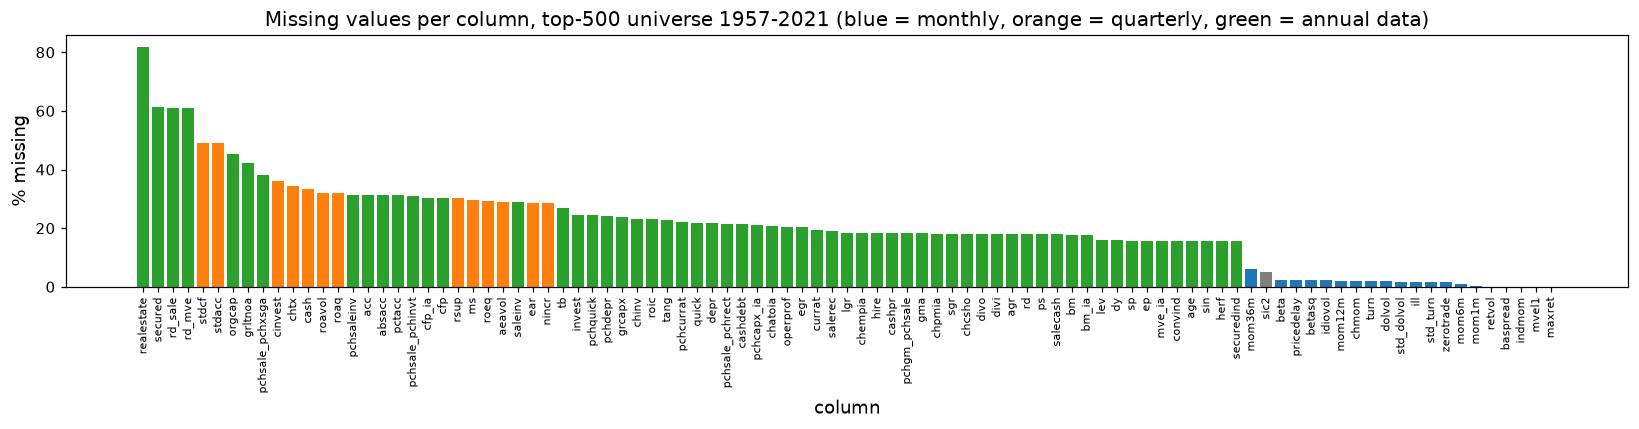

columns with 0% missing: 2, with >30% missing: 22, worst: realestate (82%)


In [14]:
miss = uni[CHARS + ['sic2']].isna().mean().mul(100).sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(15, 4))
colors = dd.reindex(miss.index)['freq'].map({'M': 'C0', 'Q': 'C1', 'A': 'C2'}).fillna('C7')
ax.bar(miss.index, miss.values, color=colors)
ax.set(title='Missing values per column, top-500 universe 1957-2021 (blue = monthly, orange = quarterly, green = annual data)',
       ylabel='% missing', xlabel='column'); ax.tick_params(axis='x', rotation=90, labelsize=7)
plt.tight_layout(); plt.show()
print(f'columns with 0% missing: {(miss == 0).sum()}, with >30% missing: {(miss > 30).sum()}, worst: {miss.index[0]} ({miss.iloc[0]:.0f}%)')

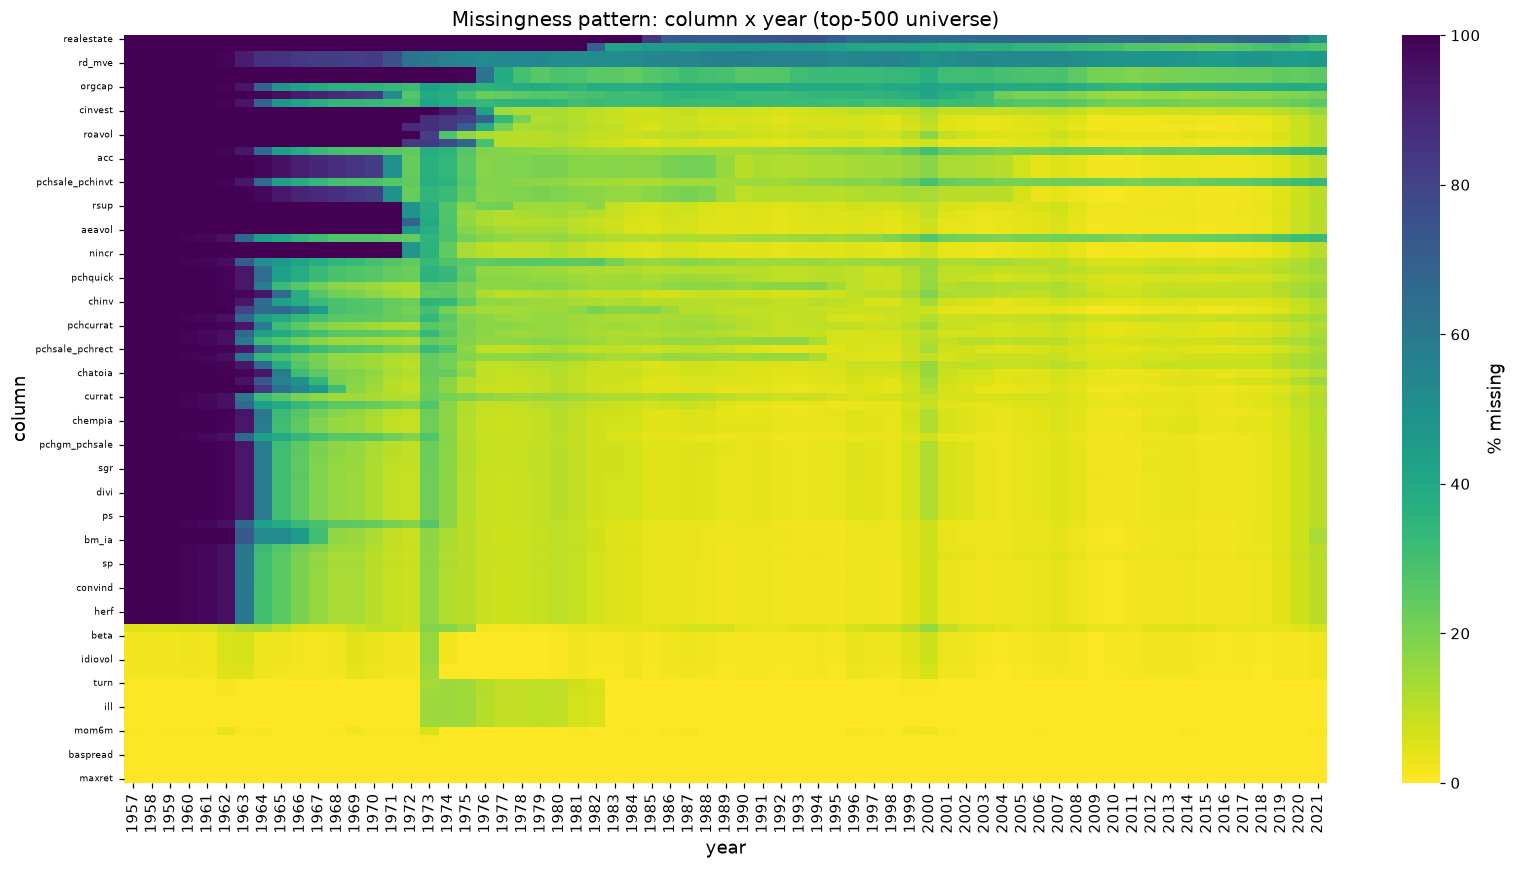

median % missing across columns, selected years:
{1960: 100.0, 1965: 32.1, 1970: 14.1, 1975: 14.2, 1980: 10.4, 1990: 4.3, 2000: 10.9, 2010: 1.9, 2021: 10.5}
first year in which the median column is <5% missing: 1985


In [15]:
yr_miss = uni.assign(year=uni.date.dt.year).groupby('year')[CHARS].apply(lambda d: d.isna().mean() * 100)
order = miss.drop('sic2').index
fig, ax = plt.subplots(figsize=(15, 8))
sns.heatmap(yr_miss[order].T, cmap='viridis_r', vmin=0, vmax=100, cbar_kws={'label': '% missing'}, ax=ax)
ax.set(title='Missingness pattern: column x year (top-500 universe)', xlabel='year', ylabel='column')
ax.tick_params(axis='y', labelsize=6); plt.tight_layout(); plt.show()
med_miss = yr_miss.median(axis=1)
first_ok = med_miss[med_miss < 5].index.min()
print('median % missing across columns, selected years:'); print(med_miss.loc[[1960, 1965, 1970, 1975, 1980, 1990, 2000, 2010, 2021]].round(1).to_dict())
print(f'first year in which the median column is <5% missing: {first_ok}')

In [16]:
modern = uni[uni.date.dt.year >= 1980]
sec_miss = modern.groupby('sector')[CHARS].apply(lambda d: d.isna().mean().mean() * 100).sort_values()
key_cols = ['rd_mve', 'invest', 'cash', 'roaq', 'stdacc', 'bm', 'lev']
sec_tab = modern.groupby('sector')[key_cols].apply(lambda d: d.isna().mean() * 100).round(1)
sec_tab.insert(0, 'avg over all 94', sec_miss)
print('% missing by sector, 1980-2021 (is missingness related to the type of firm?)'); display(sec_tab.sort_values('avg over all 94'))

% missing by sector, 1980-2021 (is missingness related to the type of firm?)


,avg over all 94,rd_mve,invest,cash,roaq,stdacc,bm,lev
sector,,,,,,,,
Wholesale,3.67,43.5,1.6,1.3,0.8,9.1,1.1,0.9
Manufacturing,3.898,16.5,2.6,3.8,3.4,11.4,1.8,1.8
Retail,4.034,37.7,2.9,2.3,2.3,11.3,1.8,1.8
Construction,6.987,96.2,5.6,0.4,0.4,55.5,0.1,0.1
Services/Tech,7.445,40.6,7.8,3.7,3.3,14.1,3.1,3.6
Mining/Energy,8.504,70,9.7,5.9,5.2,11.7,5.5,5
Transport/Utilities/Telecom,9.026,92.3,5.3,4.8,4.1,10.4,2.7,2.7
Agriculture,9.258,23.5,9.1,18.6,19.7,27.1,4.9,4.9
Public/Other,9.506,39.1,6.4,9,8.9,59.3,3.3,3.3


In [17]:
tgt = pd.Series({'target available': uni.y.notna().sum(),
                 'no next-month row (delisting, gap, or last month 2021-12)': (~uni.has_next).sum(),
                 'next-month row exists but its retvol is missing or stale (< 1e-4)': (uni.has_next & uni.y.isna()).sum()})
print('Why is the target missing? (top-500 universe)'); display(tgt.to_frame('stock-months'))

Why is the target missing? (top-500 universe)


,stock-months
target available,388502
"no next-month row (delisting, gap, or last month 2021-12)",1471
next-month row exists but its retvol is missing or stale (< 1e-4),27


**Missing-data decisions** (to be applied in the modeling pipeline):
1. **Modeling window starts in 1980**, with a 1985-start sensitivity check, because 1985 is the first year in which the median column is under 5% missing. Before roughly the mid-1970s most quarterly and many annual Compustat-based columns are almost entirely missing in this universe. That is *missing by design*: the data did not exist yet, so the values are not missing at random. The time-series EDA below uses the full 1957–2021 history of `retvol`, which is never missing.
2. **Rows without a target are dropped.**
   * **What we predict.** The response is `y` = log of `retvol` for month *t*, i.e. the stock's realized volatility in the month we forecast.
   * **Where it comes from.** It is read from the GKX file (`datashare_small.parquet`, column `retvol`), but from the **next row** (*t+1*) of the same stock (§2.4, §3.2).
   * **What "without a target" means.** For feature row *t*, `y` is missing when any of these holds:
     * there is **no row *t+1*** for that `permno`: the stock delisted, was acquired, has a gap, or row *t* is 2021-12, the last month in the file;
     * row *t+1* exists, but its `retvol` is missing or below the stale-price threshold.
   * **Why drop rather than impute.** The table above counts each case. We cannot score a forecast without an outcome, and imputing the *response* would make up the answers the model is graded on.
3. **Features are imputed with the cross-sectional median of that month** (GKX's approach), each paired with a 0/1 *was-missing* indicator for the columns with heavy missingness.
   * The median is computed within each month, so imputation never uses future data.
   * The indicator lets models learn whether missingness itself carries information (MAR/MNAR, Lecture 10).
   * Columns that are more than 50% missing after 1980 are candidates to drop, and feature selection (lasso) will decide.
4. Missingness varies by sector: for example, R&D items are often blank for financial firms. This is another reason for the missing-indicator approach rather than dropping rows.

### 3.5 Unusual values

In [18]:
nonneg = ['mvel1', 'retvol', 'baspread', 'ill', 'turn', 'std_turn', 'std_dolvol', 'idiovol', 'zerotrade', 'age', 'betasq', 'herf']
chk_rows = []
for c in nonneg:
    chk_rows.append((c, 'must be >= 0', int((uni[c] < 0).sum())))
for c in BINARY:
    chk_rows.append((c, 'must be 0/1', int((~uni[c].dropna().isin([0, 1])).sum())))
for c, hi in [('ps', 9), ('ms', 8), ('nincr', 8)]:
    chk_rows.append((c, f'integer score 0-{hi}', int((~uni[c].dropna().between(0, hi)).sum())))
chk_rows.append(('retvol', '< 1e-4 (price essentially never moved)', int((uni.retvol < 1e-4).sum())))
chk_rows.append(('maxret', '> 100% in one day', int((uni.maxret > 1).sum())))
display(pd.DataFrame(chk_rows, columns=['column', 'rule', '# violating stock-months']))

,column,rule,# violating stock-months
0,mvel1,must be >= 0,0
1,retvol,must be >= 0,0
2,baspread,must be >= 0,0
3,ill,must be >= 0,0
4,turn,must be >= 0,0
5,std_turn,must be >= 0,0
6,std_dolvol,must be >= 0,0
7,idiovol,must be >= 0,0
8,zerotrade,must be >= 0,0
9,age,must be >= 0,0


In [19]:
uni['ann_vol'] = uni.retvol * np.sqrt(252)
top = uni.nlargest(12, 'ann_vol')[['permno', 'date', 'sector', 'ann_vol', 'maxret', 'mvel1']]
top['vol_month'] = (top.date - pd.offsets.MonthEnd(1)).dt.strftime('%Y-%m')
print('Highest annualized volatilities in the universe (vol_month = month the volatility refers to):'); display(top)

Highest annualized volatilities in the universe (vol_month = month the volatility refers to):


,permno,date,sector,ann_vol,maxret,mvel1,vol_month
3217018,82775,2009-01-30,Finance,3.663,0.8935,4.935e+06,2008-12
3893969,90505,2008-11-28,Services/Tech,3.639,0.7753,5.044e+06,2008-10
2280619,69032,2008-11-28,Finance,3.53,0.7753,1.855e+07,2008-10
622968,17907,2020-07-31,Unknown,3.527,0.8375,2.437e+07,2020-06
1901696,56232,2008-11-28,Finance,2.98,0.6514,5.497e+06,2008-10
1294006,36469,2008-10-31,Finance,2.977,0.5574,7.556e+06,2008-09
2228069,66800,2008-10-31,Finance,2.977,0.4312,8.954e+06,2008-09
3756025,89301,2021-02-26,Retail,2.945,0.678,2.267e+07,2021-01
2315059,70519,2008-12-31,Finance,2.918,0.5782,4.518e+07,2008-11
3259813,83431,1999-02-26,Services/Tech,2.892,0.6296,6.24e+06,1999-01


In [20]:
skew = uni.loc[uni.date.dt.year >= 1980, CHARS].skew().abs().sort_values(ascending=False)
q = uni.loc[uni.date.dt.year >= 1980, skew.index[:10]].quantile([0, .01, .5, .99, 1]).T
q.insert(0, '|skew|', skew.iloc[:10])
print('Ten most skewed characteristics (1980+): heavy tails driven by tiny denominators'); display(q)

Ten most skewed characteristics (1980+): heavy tails driven by tiny denominators


,|skew|,0,0.01,0.5,0.99,1
rd_sale,192.8,0,0,0.02545,0.4256,124.8
ill,92.56,0,7.119e-12,3.333e-10,7.019e-08,9.539e-05
bm,45.74,-2.313,-0.04007,0.4701,3.362,127.4
cfp_ia,35.14,-58.41,-4.981,0.01739,1.337,363.7
stdacc,29.7,0.0002739,0.0183,0.09297,1.109,900.3
cashdebt,29.37,-32.43,-0.1666,0.1775,1.452,2.674
stdcf,29.09,0.0002376,0.01936,0.1024,1.557,"2,997"
chempia,26.36,-57.17,-2.185,-0.05935,0.9721,3.575
zerotrade,25.44,1.081e-10,2.561e-09,2.411e-08,1.003e-06,19.17
pchsaleinv,21.77,-0.9999,-0.6591,0.0131,1.888,30.97


**Unusual-value decisions:**
* **Almost no impossible values.**
  * The only violation of a hard rule is **one negative bid-ask spread**. A spread cannot be negative, so it is a data error and is **set to missing**.
  * Everything else (0/1 dummies, bounded scores, non-negative quantities) passes.
* **`retvol` below $10^{-4}$** (a few dozen stock-months) means the price was essentially unchanged all month: a stale quote or a halt. It is not a real "near-zero risk" reading, and its log would be an extreme outlier (about −20 versus a typical −4). It is **set to missing** in both the target and the lags.
* **Extreme volatilities are real events** (1987, 2000–02, 2008, 2020, single-stock collapses and bankruptcies), and the stress periods are exactly what the project question asks about. They are **kept**. The log transform tames their influence on squared-error loss.
* **Extreme characteristics** come from ratios with near-zero denominators (sales/inventory, % changes). They are errors in *scale*, not in fact. Rather than deleting them we **rank-transform each characteristic cross-sectionally to [−1, 1] each month** (GKX). This bounds outliers, removes units, and uses only that month's data, so it does not leak.

### 3.6 Scale of the features

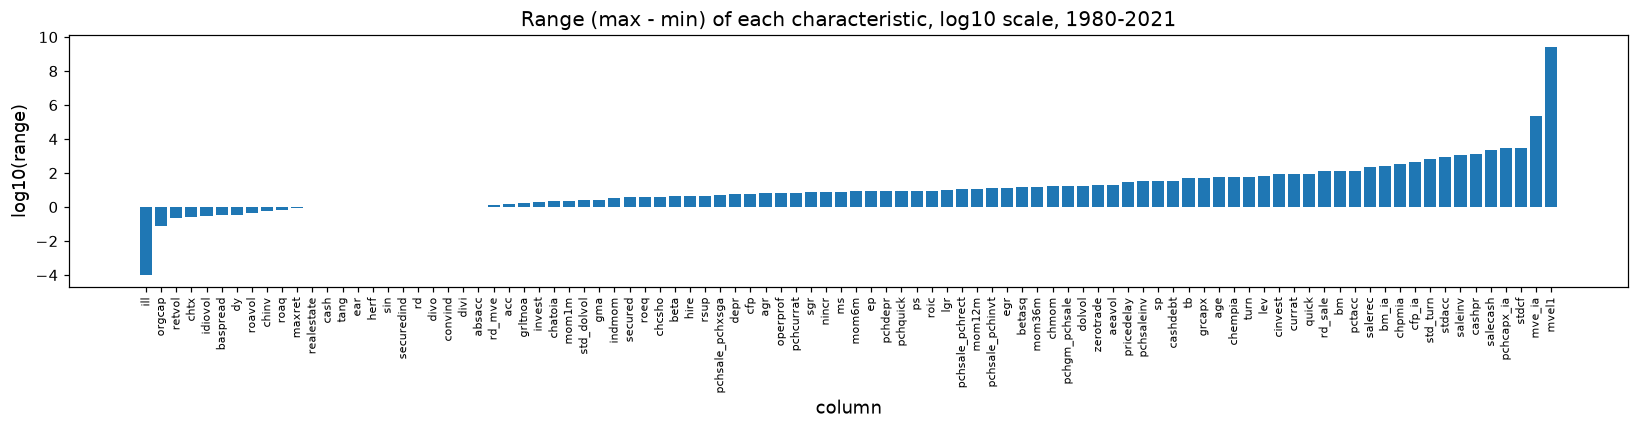

ranges span -4.0 to 9.4 orders of magnitude (smallest: ill, largest: mvel1)


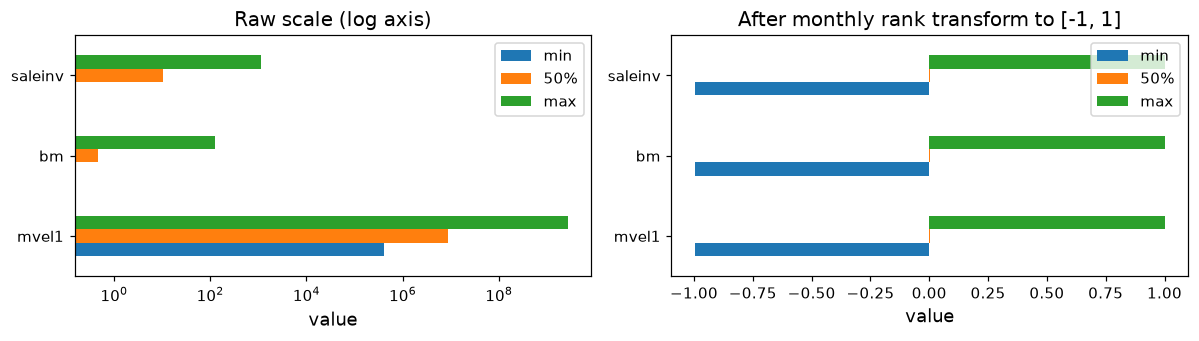

In [21]:
rng = uni.loc[uni.date.dt.year >= 1980, CHARS].agg(['min', 'max']).T
rng['range'] = rng['max'] - rng['min']
rng = rng.sort_values('range')
fig, ax = plt.subplots(figsize=(15, 4))
ax.bar(rng.index, np.log10(rng['range'].clip(lower=1e-6)), color='C0')
ax.set(title='Range (max - min) of each characteristic, log10 scale, 1980-2021', ylabel='log10(range)', xlabel='column')
ax.tick_params(axis='x', rotation=90, labelsize=7); plt.tight_layout(); plt.show()
print(f"ranges span {np.log10(rng['range'].min()):.1f} to {np.log10(rng['range'].max()):.1f} orders of magnitude "
      f"(smallest: {rng.index[0]}, largest: {rng.index[-1]})")

def cs_rank(df, cols):                        # cross-sectional rank -> [-1, 1], NaN preserved
    r = df.groupby('date')[cols].rank(pct=True)
    return 2 * r - 1
demo = uni.loc[uni.date.dt.year >= 1980, ['date', 'mvel1', 'bm', 'saleinv']]
demo_r = cs_rank(demo, ['mvel1', 'bm', 'saleinv'])
fig, axes = plt.subplots(1, 2, figsize=(11, 3.2))
demo[['mvel1', 'bm', 'saleinv']].describe().loc[['min', '50%', 'max']].T.plot.barh(ax=axes[0], logx=True)
axes[0].set(title='Raw scale (log axis)', xlabel='value')
demo_r.describe().loc[['min', '50%', 'max']].T.plot.barh(ax=axes[1])
axes[1].set(title='After monthly rank transform to [-1, 1]', xlabel='value'); plt.tight_layout(); plt.show()

**Scale decision.** The characteristics differ by many orders of magnitude: `mvel1` is in thousands of dollars, while most ratios are near 0. Ridge, lasso, kNN and neural networks all need comparable scales.
* **Stock characteristics:** monthly rank transform to [−1, 1], as above.
* **HAR lags and macro/factor variables:** z-scored with the mean and standard deviation of the *training window only*, refit at every walk-forward step to avoid leakage.

Trees do not need scaling, but using the same inputs for all models keeps the comparison fair.

### 3.7 Class imbalance → *imbalance in regimes, not classes*
This is a regression task, so there are no classes. The analogous problem is that **stress months are rare**, while the project asks whether gains survive in stress periods. We define stress months as months whose S&P realized variance (`svar`) is in the top 10% of the *training-period* distribution, and count them.

In [22]:
svar_m = gw['svar'].copy()
thr = svar_m.loc['1980-01':'2010-12'].quantile(0.90)                    # threshold from training period only
stress = (svar_m > thr).rename('stress')
s = stress.loc['1980-01':'2021-11']
by = pd.DataFrame({'stress months': [s.loc[:'2010-12'].sum(), s.loc['2011-01':'2015-12'].sum(), s.loc['2016-01':].sum()],
                   'total months': [s.loc[:'2010-12'].size, s.loc['2011-01':'2015-12'].size, s.loc['2016-01':].size]},
                  index=['train 1980-2010', 'validation 2011-2015', 'test 2016-2021'])
by['% stress'] = 100 * by['stress months'] / by['total months']; display(by)
print('stress months in test window:', [str(p) for p in s.loc['2016-01':][s.loc['2016-01':]].index])

,stress months,total months,% stress
train 1980-2010,38,372,10.22
validation 2011-2015,5,60,8.333
test 2016-2021,5,71,7.042


stress months in test window: ['2018-02', '2018-12', '2020-03', '2020-04', '2020-06']


The test window contains only a handful of stress months, which are concentrated in the 2020 COVID shock, with 2018 Q4 borderline. A "stress-period" comparison on the test set alone therefore rests on few independent episodes. The plan has two parts:
1. Report the calm/stress split on the test set **with bootstrap confidence intervals**, resampling whole months (block bootstrap).
2. Add a *secondary* out-of-sample check over the 2008–09 crisis, where models are trained only on data up to 2007.

### 3.8 Information-leakage audit (stock panel)

In [23]:
X = uni.loc[uni.y.notna() & (uni.date.dt.year >= 1980)]
corr_y = X[CHARS + ['har_1', 'har_3', 'har_12']].corrwith(X['y']).abs().sort_values(ascending=False)
print('Largest |correlation| between a feature in row t and the target y_t (month t volatility):')
display(corr_y.head(10).to_frame('|corr with y|'))
print('Any feature with |corr| > 0.95 (would suggest the feature IS the target)?', bool((corr_y > 0.95).any()))

Largest |correlation| between a feature in row t and the target y_t (month t volatility):


,|corr with y|
har_3,0.7189
har_1,0.6966
har_12,0.6648
baspread,0.6634
retvol,0.6245
idiovol,0.5267
maxret,0.4937
beta,0.4002
betasq,0.3858
turn,0.2806


Any feature with |corr| > 0.95 (would suggest the feature IS the target)? False


**Leakage checks done (stock panel):**
1. **Timing verified empirically (§2.4).** Row *t* = information up to the end of month *t−1*, and the target comes strictly from row *t+1*.
2. **No feature is a disguised copy of the target.** The strongest correlations are with past volatility (`retvol`/HAR lags, `idiovol`, `maxret`, `baspread`), roughly 0.7–0.8. That is expected persistence, not leakage, because they all describe month *t−1* or earlier.
3. **The universe is chosen with lagged size**, so we never select on future information. Delisted stocks remain in the sample.
4. **All preprocessing statistics are computed either within a month (ranks, medians) or on the training window only (z-scores, stress threshold).**
5. **A 1-month embargo** separates each training window from the next validation/test window. Monthly targets do not overlap, so this is a safety margin rather than a necessity. (With overlapping weekly targets the original plan needed a 5-day gap.)

Anthony (§6) repeats this audit on the merged table that includes macro data, which have their own publication lags.

### 3.9 Save the cleaned stock panel

In [24]:
keep = ['permno', 'date', 'target_month', 'sic2', 'sector', 'size_rank', 'y', 'har_1', 'har_3', 'har_12'] + CHARS
clean = uni.loc[uni.y.notna(), keep].reset_index(drop=True)
clean.to_parquet(os.path.join(OUT, 'panel_top500_clean.parquet'), index=False)
modeling = clean[clean.date.dt.year >= 1980]
print(f'cleaned panel (all years): {clean.shape[0]:,} rows x {clean.shape[1]} cols; '
      f'modeling window 1980-2021: {modeling.shape[0]:,} rows, {modeling.permno.nunique():,} stocks; '
      f'file = {os.path.getsize(os.path.join(OUT, "panel_top500_clean.parquet"))/2**20:.0f} MB')

cleaned panel (all years): 388,502 rows x 104 cols; modeling window 1980-2021: 250,719 rows, 2,458 stocks; file = 71 MB


## 4. Time-series EDA  *(owner: YiTong)*

MS3 is where the full EDA happens. Here we look at the **time-series properties of the response**, because they determine which models make sense. Anything that feeds a modeling choice (ARIMA order, HAR clustering) uses **target months up to 2015 only**, so the test period stays untouched.

### 4.1 Distribution of the response

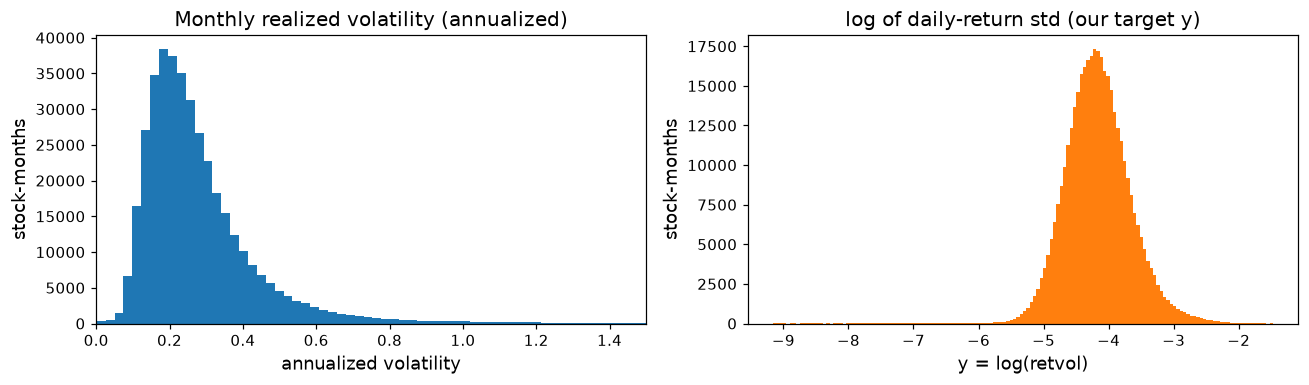

raw vol skewness 3.29  vs  log vol skewness 0.13


In [25]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
v = uni.loc[uni.y.notna()]
axes[0].hist(np.exp(v.y) * np.sqrt(252), bins=150, color='C0'); axes[0].set_xlim(0, 1.5)
axes[0].set(title='Monthly realized volatility (annualized)', xlabel='annualized volatility', ylabel='stock-months')
axes[1].hist(v.y, bins=150, color='C1')
axes[1].set(title='log of daily-return std (our target y)', xlabel='y = log(retvol)', ylabel='stock-months')
plt.tight_layout(); plt.show()
print(f'raw vol skewness {pd.Series(np.exp(v.y)).skew():.2f}  vs  log vol skewness {v.y.skew():.2f}')

Raw volatility is strongly right-skewed, while its log is close to symmetric. That is the standard reason to model **log** volatility: squared-error loss is not dominated by a few crash months, and linear models fit far better.

### 4.2 Volatility through time: clustering and regimes

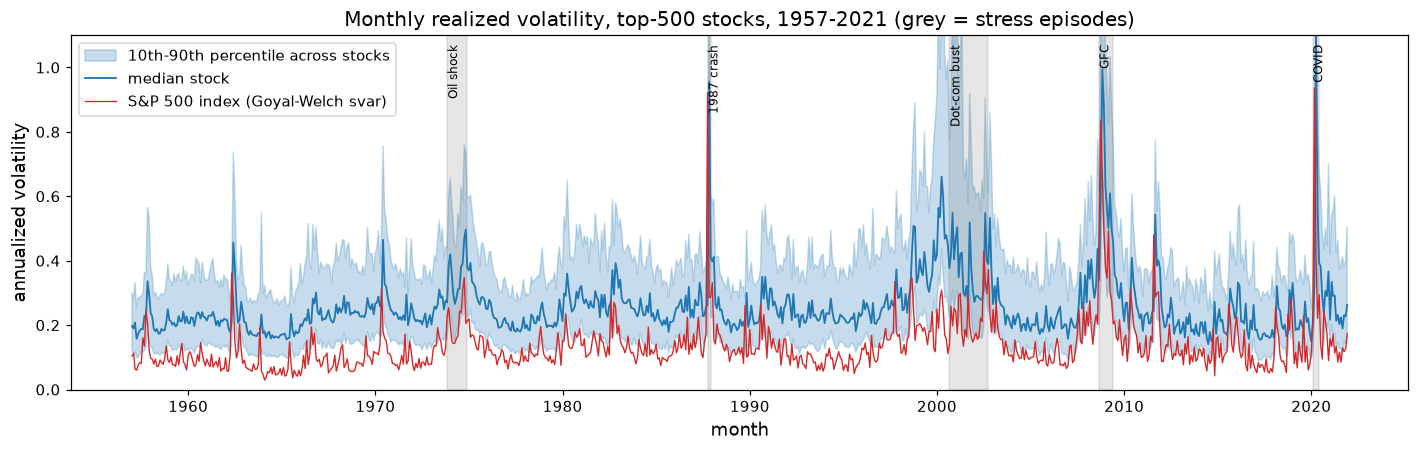

In [26]:
agg = uni.groupby('date')['lrv'].agg(med='median', q10=lambda s: s.quantile(.1), q90=lambda s: s.quantile(.9))
vol_month = agg.index - pd.offsets.MonthEnd(1)            # row t describes month t-1
mkt_vol = np.sqrt(gw['svar'] * 12)
fig, ax = plt.subplots(figsize=(13, 4.2))
ax.fill_between(vol_month, np.exp(agg.q10) * np.sqrt(252), np.exp(agg.q90) * np.sqrt(252), color='C0', alpha=.25, label='10th-90th percentile across stocks')
ax.plot(vol_month, np.exp(agg.med) * np.sqrt(252), color='C0', lw=1.2, label='median stock')
ax.plot(mkt_vol.loc['1957-01':'2021-12'].index.to_timestamp(), mkt_vol.loc['1957-01':'2021-12'].values, color='C3', lw=.9, label='S&P 500 index (Goyal-Welch svar)')
for a, b, lab in STRESS_EPISODES:
    ax.axvspan(pd.Timestamp(a), pd.Timestamp(b), color='grey', alpha=.2)
    ax.text(pd.Timestamp(a), 1.07, lab, fontsize=8, rotation=90, va='top')
ax.set(title='Monthly realized volatility, top-500 stocks, 1957-2021 (grey = stress episodes)', xlabel='month', ylabel='annualized volatility', ylim=(0, 1.1))
ax.legend(loc='upper left'); plt.tight_layout(); plt.show()

Three features are visible:
1. **Volatility clusters**: calm and turbulent months come in runs.
2. Every stress episode raises *all* stocks together, so a large share of each stock's volatility is a **common market factor**. This is why market-level inputs (lagged `svar`, VIX-like variables) should help a pooled model.
3. Single-stock volatility sits well above index volatility because diversification cancels idiosyncratic risk.

### 4.3 Persistence: autocorrelation of log volatility

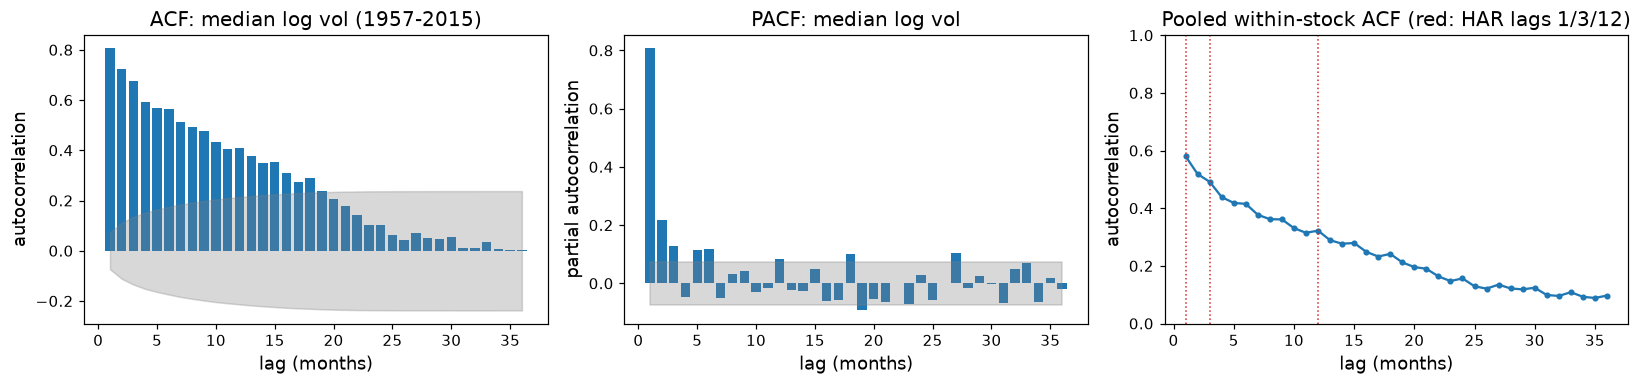

pooled within-stock ACF at lags 1, 3, 6, 12, 24, 36: [0.58  0.492 0.415 0.322 0.157 0.097]


,lb_stat,lb_pvalue
6,"1,874",0
12,"2,772",0
24,"3,365",0


In [27]:
agg_ts = pd.Series(agg['med'].values, index=pd.PeriodIndex(vol_month, freq='M'))
fit_ts = agg_ts.loc[:'2015-12']
fig, axes = plt.subplots(1, 3, figsize=(15, 3.6))
L = 36
a, ci = acf(fit_ts, nlags=L, alpha=.05); p, pci = pacf(fit_ts, nlags=L, alpha=.05)
axes[0].bar(range(1, L + 1), a[1:]); axes[0].fill_between(range(1, L + 1), ci[1:, 0] - a[1:], ci[1:, 1] - a[1:], color='grey', alpha=.3)
axes[0].set(title='ACF: median log vol (1957-2015)', xlabel='lag (months)', ylabel='autocorrelation')
axes[1].bar(range(1, L + 1), p[1:]); axes[1].fill_between(range(1, L + 1), pci[1:, 0] - p[1:], pci[1:, 1] - p[1:], color='grey', alpha=.3)
axes[1].set(title='PACF: median log vol', xlabel='lag (months)', ylabel='partial autocorrelation')
# pooled within-stock ACF: demean each stock, then correlate x_t with x_{t-k} only across consecutive months
P = gkx.loc[gkx.permno.isin(uni.permno.unique()) & (gkx.date <= '2016-01-31'), ['permno', 'm', 'lrv']].dropna()
P['x'] = P.lrv - P.groupby('permno').lrv.transform('mean')
base = P.set_index(['permno', 'm'])['x']
pooled = []
for k in range(1, L + 1):
    lagged = P.assign(m=P.m + k).set_index(['permno', 'm'])['x']
    j = pd.concat([base, lagged.rename('xl')], axis=1, join='inner')
    pooled.append(np.corrcoef(j.iloc[:, 0], j.xl)[0, 1])
axes[2].plot(range(1, L + 1), pooled, 'o-', ms=3)
for k in (1, 3, 12): axes[2].axvline(k, color='C3', ls=':', lw=1)
axes[2].set(title='Pooled within-stock ACF (red: HAR lags 1/3/12)', xlabel='lag (months)', ylabel='autocorrelation', ylim=(0, 1))
plt.tight_layout(); plt.show()
print('pooled within-stock ACF at lags 1, 3, 6, 12, 24, 36:', np.round([pooled[i - 1] for i in (1, 3, 6, 12, 24, 36)], 3))
lb = acorr_ljungbox(fit_ts, lags=[6, 12, 24], return_df=True); display(lb)

The ACF **decays slowly**: correlations are still clearly positive after two to three years. This is *long memory*.
* A single AR(1) term would make the ACF decay geometrically, which is far too fast to match this.
* The **HAR model** handles it cheaply by averaging past volatility over a short horizon (1 month), a medium one (3 months) and a long one (12 months).

The partial autocorrelations beyond the first few lags are small. The Ljung–Box test strongly rejects "no autocorrelation". So volatility *is* forecastable, which is the premise of the project.

### 4.4 Stationarity

In [28]:
def stat_tests(x):
    adf_p = adfuller(x, autolag='AIC')[1]; kpss_p = kpss(x, regression='c', nlags='auto')[1]
    return adf_p, kpss_p
adf_p, kpss_p = stat_tests(fit_ts.values)
print(f'median log vol 1957-2015: ADF p = {adf_p:.4f} (H0: unit root)  |  KPSS p = {kpss_p:.3f} (H0: stationary)')
# per-stock: stocks with >= 120 consecutive months of lrv before 2016
P2 = gkx.loc[gkx.permno.isin(uni.permno.unique()) & (gkx.date <= '2016-01-31'), ['permno', 'lrv']].dropna()
cnt = P2.groupby('permno').size(); elig = cnt[cnt >= 120].index
pick = RNG.choice(elig, size=min(300, len(elig)), replace=False)
out = []
for pm in pick:
    x = P2.loc[P2.permno == pm, 'lrv'].values
    out.append(stat_tests(x))
out = np.array(out)
print(f'{len(pick)} random stocks with >=120 months: ADF rejects unit root (p<.05) for {100*(out[:,0]<.05).mean():.0f}%; '
      f'KPSS rejects stationarity (p<.05) for {100*(out[:,1]<.05).mean():.0f}%')

median log vol 1957-2015: ADF p = 0.0004 (H0: unit root)  |  KPSS p = 0.039 (H0: stationary)


300 random stocks with >=120 months: ADF rejects unit root (p<.05) for 71%; KPSS rejects stationarity (p<.05) for 62%


**How to read the two tests.**
* **ADF** tests the null "unit root", meaning shocks never die out; rejecting it is evidence *for* stationarity.
* **KPSS** tests the null "stationary"; rejecting it is evidence *against* stationarity.

When ADF rejects *and* KPSS also rejects, that is the classic signature of a **long-memory (fractionally integrated) series**. It is mean-reverting, but too slowly for a short-memory model.

**Implications:**
* Model **levels of log volatility** without first-differencing them, since differencing would throw away the mean-reversion that makes forecasting possible.
* Use HAR-type averages to capture the slow decay.
* Expect slow drifts in the volatility level over decades, so use **expanding or rolling training windows** and re-estimate the models over time.

### 4.5 Automatic ARIMA order selection (analogue of R's `auto.arima`)
`pmdarima` is not available, so we run a small AIC grid search with `statsmodels`. This is the same logic `auto.arima` uses.

In [29]:
y_fit = fit_ts.loc['1980-01':].astype(float).values
grid = []
for d in (0, 1):
    for p_ in range(0, 4):
        for q_ in range(0, 4):
            try:
                r = ARIMA(y_fit, order=(p_, d, q_), trend='c' if d == 0 else 'n').fit()
                grid.append({'order': (p_, d, q_), 'AIC': r.aic, 'BIC': r.bic})
            except Exception:
                pass
grid = pd.DataFrame(grid).sort_values('AIC')
display(grid.head(6))
best = ARIMA(y_fit, order=grid.iloc[0]['order'], trend='c' if grid.iloc[0]['order'][1] == 0 else 'n').fit()
print('best by AIC:', grid.iloc[0]['order'], '| Ljung-Box p of residuals (lag 12):',
      round(acorr_ljungbox(best.resid, lags=[12], return_df=True)['lb_pvalue'].iloc[0], 3))

,order,AIC,BIC
15,"(3, 0, 3)",-285.3,-252.7
31,"(3, 1, 3)",-282.3,-253.8
14,"(3, 0, 2)",-278.8,-250.3
27,"(2, 1, 3)",-276.7,-252.3
13,"(3, 0, 1)",-266.5,-242.1
12,"(3, 0, 0)",-265.6,-245.3


best by AIC: (3, 0, 3) | Ljung-Box p of residuals (lag 12): 0.14


The AIC grid chooses **ARMA(3,3) on levels (d = 0)**, and its residuals pass the Ljung–Box test. Two points support this:
* The undifferenced model winning agrees with the ADF result that the series is mean-reverting.
* Needing several AR *and* MA terms is another symptom of long memory: a short-memory model has to stack lags to mimic slow decay. HAR does the same job with only 3 coefficients.

For the market-wide series this gives a second "traditional time-series" baseline. ARIMA is also the first stage of the optional *ARIMA + ML-on-residuals* hybrid described in the outline.

### 4.6 Per-stock HAR fits and clustering stocks by their volatility dynamics
For each stock with at least 120 usable months whose target month is before 2016, we fit
$y_t = b_0 + b_1\,\text{har\_1} + b_2\,\text{har\_3} + b_3\,\text{har\_12} + \varepsilon_t$ by OLS.

2139 stocks; median in-sample R2 = 0.39


,mean,25%,50%,75%
b0,-0.9344,-1.169,-0.8465,-0.5955
b_1m,0.2167,0.1371,0.2124,0.2849
b_3m,0.297,0.1969,0.3113,0.4051
b_12m,0.2646,0.1591,0.2623,0.3638
R2,0.3901,0.2826,0.3852,0.4956
n,333,203,293,439
persistence,0.7783,0.7217,0.7996,0.8619


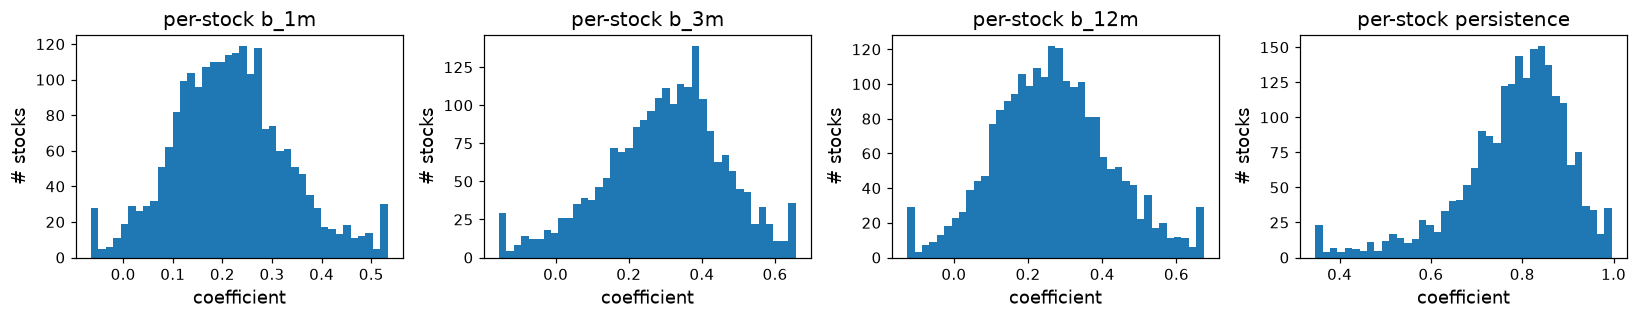

In [30]:
H = gkx.loc[gkx.permno.isin(uni.permno.unique()) & (gkx.date <= VAL_END), ['permno', 'y', 'har_1', 'har_3', 'har_12']].dropna()
cnt = H.groupby('permno').size(); H = H[H.permno.isin(cnt[cnt >= 120].index)]
coefs = []
for pm, g in H.groupby('permno'):
    Xh = np.column_stack([np.ones(len(g)), g[['har_1', 'har_3', 'har_12']].values]); yh = g.y.values
    b, *_ = np.linalg.lstsq(Xh, yh, rcond=None)
    r2 = 1 - ((yh - Xh @ b) ** 2).sum() / ((yh - yh.mean()) ** 2).sum()
    coefs.append((pm, *b, r2, len(g)))
C = pd.DataFrame(coefs, columns=['permno', 'b0', 'b_1m', 'b_3m', 'b_12m', 'R2', 'n']).set_index('permno')
C['persistence'] = C[['b_1m', 'b_3m', 'b_12m']].sum(axis=1)
print(f'{len(C)} stocks; median in-sample R2 = {C.R2.median():.2f}'); display(C.describe().T[['mean', '25%', '50%', '75%']])
fig, axes = plt.subplots(1, 4, figsize=(15, 3))
for ax, c in zip(axes, ['b_1m', 'b_3m', 'b_12m', 'persistence']):
    ax.hist(C[c].clip(C[c].quantile(.01), C[c].quantile(.99)), bins=40); ax.set(title=f'per-stock {c}', xlabel='coefficient', ylabel='# stocks')
plt.tight_layout(); plt.show()

**What the table `C` is.** One row per stock (index = `permno`) holding that stock's own fitted HAR model:

| Column | Meaning |
|---|---|
| `b0` | intercept: the stock's baseline log-volatility level |
| `b_1m`, `b_3m`, `b_12m` | weights on last month's (`har_1`), last quarter's (`har_3`) and last year's (`har_12`) volatility |
| `R2` | share of the variation in that stock's monthly log volatility the fit explains, in-sample |
| `n` | number of months used for the fit |
| `persistence` | `b_1m + b_3m + b_12m`: how much of a volatility shock carries into next month. Below 1 means it fades over time (mean reversion). |

So `C` turns ~2,100 long time series into ~2,100 short "fingerprints" of how each stock's volatility remembers the past.

**What the clustering does: grouping stocks with similar volatility memory.**

*Plain version.* Picture each stock as a dot on a 3-D chart, placed by its three weights (1-month, 3-month, 12-month). Some stocks react mostly to last month, others mostly to last year. Clustering asks the computer to sort the dots into **k groups** so that dots in the same group sit close together. **k is the number of groups**; k = 2 means "two types of stock". Each stock gets a group label, saved in the column `C['cluster']`.

*Technical version.*
* **Inputs.** The three weights are clipped at their 1st/99th percentiles (a handful of short-history stocks have extreme estimates). They are then standardized (`StandardScaler`: mean 0, std 1), so that no weight dominates the distances just because of its scale.
* **K-means** (`KMeans(k)`) picks k cluster centres to minimise the total squared distance from each stock to its nearest centre. It alternates two steps: assign each stock to its nearest centre, then move each centre to the mean of its stocks. `n_init=10` restarts from 10 random starts and keeps the best; `random_state=0` makes the result reproducible.
* **Choosing k with the silhouette score** (`silhouette_score`). For each stock, let *a* = its mean distance to the other stocks in its own cluster and *b* = its mean distance to the stocks of the nearest *other* cluster. Its silhouette is $(b-a)/\max(a,b)$.
  * The value is in [−1, 1]. **1** means clearly in the right group; **0** means on the border between two groups; **negative** means probably in the wrong group.
  * The score is the average over stocks.
  * We try k = 2, …, 6 and keep the k with the highest average. That is an automatic, data-driven choice of k, in the same spirit as choosing ARIMA orders by AIC.
* **Sector check.** We cross-tabulate the clusters against sector, to see whether they just rediscover industries.

In [31]:
# Z: stocks x 3 matrix of the HAR weights, clipped at 1%/99% and standardized -> the points to cluster
Z = StandardScaler().fit_transform(C[['b_1m', 'b_3m', 'b_12m']].clip(C[['b_1m', 'b_3m', 'b_12m']].quantile(.01), C[['b_1m', 'b_3m', 'b_12m']].quantile(.99), axis=1))
# for each candidate number of groups k: run k-means, then score how well-separated the groups are (silhouette, -1..1)
sil = {k: silhouette_score(Z, KMeans(k, n_init=10, random_state=0).fit_predict(Z)) for k in range(2, 7)}
k_best = max(sil, key=sil.get)                                       # k with the best separation
C['cluster'] = KMeans(k_best, n_init=10, random_state=0).fit_predict(Z)
sec_of = uni.groupby('permno').sector.agg(lambda s: s.mode().iloc[0])
C['sector'] = sec_of.reindex(C.index)
print('silhouette by k:', {k: round(v, 3) for k, v in sil.items()}, '-> k =', k_best)
display(C.groupby('cluster')[['b_1m', 'b_3m', 'b_12m', 'persistence', 'R2']].median().assign(n_stocks=C.cluster.value_counts()))
display(pd.crosstab(C.sector, C.cluster, normalize='columns').mul(100).round(0))

silhouette by k: {2: 0.308, 3: 0.29, 4: 0.269, 5: 0.261, 6: 0.271} -> k = 2


,b_1m,b_3m,b_12m,persistence,R2,n_stocks
cluster,,,,,,
0,0.2615,0.1732,0.3638,0.8028,0.3536,900
1,0.177,0.3902,0.1958,0.7973,0.4014,1239


cluster,0,1
sector,,
Agriculture,0,0
Construction,0,1
Finance,11,18
Manufacturing,40,37
Mining/Energy,7,7
Public/Other,0,1
Retail,7,5
Services/Tech,10,9
Transport/Utilities/Telecom,13,15


**Reading the HAR fits.**
* For the median stock, all three horizons get positive weight (about 0.21 / 0.31 / 0.26), with a persistence (their sum) of about 0.80 < 1, i.e. mean reversion. The median in-sample R² is about 0.39.
* The spread of coefficients across stocks shows that **stocks differ in how their volatility remembers shocks**.
* The silhouette score picks **k = 2** clusters:
  * a **long-memory** group, where the 12-month weight dominates;
  * a **medium-memory** group, where the 3-month weight dominates.
* Both clusters have similar sector mixes, so the dynamics are **not just an industry effect**. The silhouette scores are modest (about 0.3), so this is a soft structure rather than sharply separated groups.

Clustering is an *optional extension* under the staff caveats. Its possible use in MS3/MS4 is to add `cluster` as a feature, or to fit one pooled model per cluster (partial pooling), which sits between per-stock HAR and one pooled model for all stocks.

### 4.7 Cross-section: size and sector

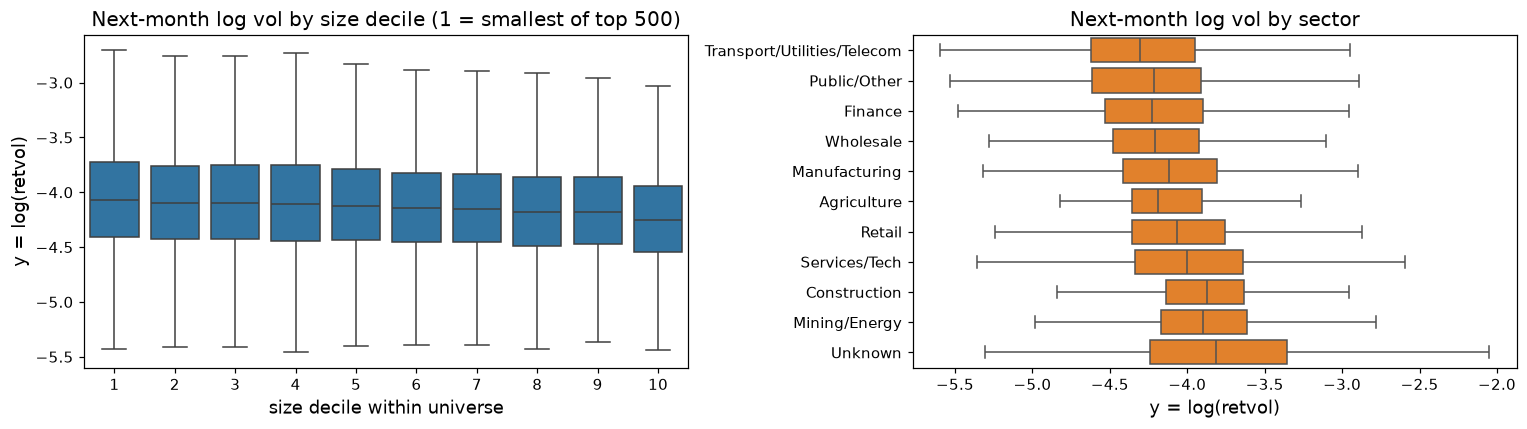

In [32]:
m80 = uni[(uni.date.dt.year >= 1980) & uni.y.notna()].copy()
m80['size_decile'] = m80.groupby('date').mvel1.transform(lambda s: pd.qcut(s.rank(method='first'), 10, labels=False) + 1)
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
sns.boxplot(data=m80.sample(60000, random_state=0), x='size_decile', y='y', ax=axes[0], showfliers=False, color='C0')
axes[0].set(title='Next-month log vol by size decile (1 = smallest of top 500)', xlabel='size decile within universe', ylabel='y = log(retvol)')
order_s = m80.groupby('sector').y.median().sort_values().index
sns.boxplot(data=m80.sample(60000, random_state=0), y='sector', x='y', order=order_s, ax=axes[1], showfliers=False, color='C1')
axes[1].set(title='Next-month log vol by sector', xlabel='y = log(retvol)', ylabel='')
plt.tight_layout(); plt.show()

Inside the top 500, volatility falls *modestly* with size. The largest decile is the calmest, and the effect is much weaker than across all CRSP stocks. Volatility also differs systematically across sectors: utilities/telecom and finance are the calmest, services/tech and mining/energy the most volatile. 'Unknown' (missing `sic2`, about 5% of rows) is the most dispersed group. These are **cross-sectional** signals that a per-stock HAR cannot use but a pooled model can. They are the main hypothesis for why ML could beat HAR.

### 4.8 Seasonality

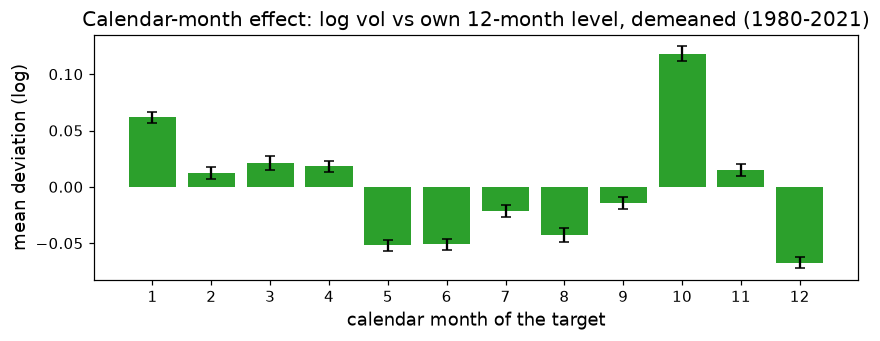

In [33]:
m80['dev'] = m80.y - m80.har_12                                   # vol relative to the stock's own 12-month level
m80['dev'] -= m80['dev'].mean()                                    # remove constant Jensen gap (log of mean var > mean of log)
m80['cal_month'] = m80.target_month.dt.month
sea = m80.groupby('cal_month').dev.agg(['mean', 'sem'])
fig, ax = plt.subplots(figsize=(8, 3.2))
ax.bar(sea.index, sea['mean'], yerr=1.96 * sea['sem'], color='C2', capsize=3)
ax.set(title='Calendar-month effect: log vol vs own 12-month level, demeaned (1980-2021)', xlabel='calendar month of the target', ylabel='mean deviation (log)')
ax.set_xticks(range(1, 13)); plt.tight_layout(); plt.show()

There is a real but small calendar pattern:
* **October** is the most volatile month (1987, 2008 and other autumn sell-offs);
* **December** and late spring/summer are the calmest;
* January, April, July and October are earnings-season months, but the pattern is not purely an earnings-season effect.

The effect is small compared with swings across regimes. It costs almost nothing to include as month-of-year dummies, so we will let the models decide whether it is worth keeping.

#### Should we use a seasonal GARCH model?

*Plain version.* A GARCH model is a classic tool that guesses "how nervous will the market be tomorrow" from how big recent price moves were. A *seasonal* (periodic) GARCH also lets the answer depend on the time of year, e.g. "Octobers tend to be rougher".

It is a sensible idea, but it fits our data poorly for three reasons:
1. **We already observe volatility directly.** GARCH was built for the case where you only see returns and must *infer* volatility from them. We are given each month's measured volatility (`retvol`), which is more accurate.
2. **GARCH needs many returns per stock.** With monthly data a stock has about 12 returns a year. A seasonal GARCH would need to estimate several extra parameters for each calendar month from roughly 30–40 Octobers per stock, which is far too little data.
3. **The calendar effect is small** (see the chart above).

So we test the *same idea* in the simpler form that suits our data: add 11 calendar-month on/off variables to the HAR regression and check whether forecasts improve.

*Technical version.*
* **Where seasonality would enter.** A periodic GARCH, e.g. Bollerslev & Ghysels (1996), $\sigma^2_t = \omega_{s(t)} + \alpha_{s(t)}\varepsilon^2_{t-1} + \beta_{s(t)}\sigma^2_{t-1}$ with season $s(t)$, models the *latent* conditional variance of *returns*.
* **Why a realized-volatility model is better here.** Realized volatility is a far less noisy measure of $\sigma_t$ than a squared monthly return, so HAR-on-RV models generally forecast better than GARCH on the same horizon. GARCH would also need per-stock monthly return series, which we only have indirectly through `mom1m`, and $\omega_s, \alpha_s, \beta_s$ would be poorly identified with about 40 observations per season.
* **The test: HAR with calendar dummies.** The seasonal analogue in our framework is a HAR-X model, $y_t = b_0 + \sum_{m=2}^{12} \gamma_m \mathbb{1}[\text{month}(t)=m] + b_1\text{har\_1} + b_2\text{har\_3} + b_3\text{har\_12} + \varepsilon_t$.
  * It is fit pooled on target months 1980–2010 and scored on the 2011–2015 validation months. The test window is never touched.
* **Optional extension for MS3.** If this helps, fit a GARCH(1,1) with calendar dummies on a *market* return series (`ff['Mkt-RF']`, about 750 months) as an extra traditional baseline for the aggregate series. `arch` supports regressors only in the mean equation, so seasonal variance terms would need a custom likelihood. That is a reasonable item for Cathy's §5 if time allows.

In [34]:
# Pooled HAR vs HAR + calendar-month dummies: train target months 1980-2010, evaluate on validation 2011-2015
S = uni.loc[(uni.date.dt.year >= 1980) & (uni.target_month <= VAL_END), ['y', 'har_1', 'har_3', 'har_12', 'target_month']].dropna()
S['cal_month'] = S.target_month.dt.month
def design(d, seasonal):
    X = [np.ones(len(d)), d.har_1, d.har_3, d.har_12]
    if seasonal:
        X += [(d.cal_month == mth).astype(float) for mth in range(2, 13)]       # January = baseline
    return np.column_stack(X)
tr, va = S[S.target_month <= TRAIN_END], S[S.target_month > TRAIN_END]
rows = []
for name, seas in [('HAR', False), ('HAR + 11 calendar-month dummies', True)]:
    Xtr, Xva = design(tr, seas), design(va, seas)
    b, *_ = np.linalg.lstsq(Xtr, tr.y.values, rcond=None)
    rss = ((tr.y.values - Xtr @ b) ** 2).sum()
    rows.append({'model': name, 'n params': Xtr.shape[1], 'train RSS': rss,
                 'train MSE': rss / len(tr), 'validation MSE': ((va.y.values - Xva @ b) ** 2).mean()})
res_s = pd.DataFrame(rows).set_index('model')
F = ((res_s['train RSS'].iloc[0] - res_s['train RSS'].iloc[1]) / 11) / (res_s['train RSS'].iloc[1] / (len(tr) - res_s['n params'].iloc[1]))
res_s['validation MSE change vs HAR (%)'] = 100 * (res_s['validation MSE'] / res_s['validation MSE'].iloc[0] - 1)
display(res_s.drop(columns='train RSS'))
print(f'train rows {len(tr):,}, validation rows {len(va):,}; nested F-statistic for the 11 dummies (train) = {F:.1f}. '
      f'Caveat: rows are not independent (stocks in the same month move together), so this F overstates '
      f'significance; validation MSE is the honest check.')

,n params,train MSE,validation MSE,validation MSE change vs HAR (%)
model,,,,
HAR,4,0.1164,0.1253,0
HAR + 11 calendar-month dummies,15,0.1127,0.1242,-0.8721


train rows 181,716, validation rows 29,477; nested F-statistic for the 11 dummies (train) = 541.1. Caveat: rows are not independent (stocks in the same month move together), so this F overstates significance; validation MSE is the honest check.


**Result of the seasonality test.**

*Plain version.* Telling the model which calendar month it is forecasting makes its validation-period errors only **about 1% smaller**. That is a real but tiny gain. A seasonal GARCH would spend far more effort to capture the same small effect, so we skip it and keep the month labels as a cheap optional input.

*Technical version.*
* **In-sample:** the nested F-statistic is very large (~540, with 11 and ~180k degrees of freedom). It is inflated, though, because errors are strongly correlated within a month: 500 stocks share one market shock. With only ~31 Octobers in training, the effective sample for each calendar month is small.
* **Out-of-sample (2011–2015):** validation MSE falls by about 0.9% (0.1253 → 0.1242). That validation window has only 5 observations of each calendar month, so the gain is fragile.
* **Decision:**
  * month-of-year dummies are a candidate feature for the pooled models, kept only if they survive walk-forward validation and lasso selection;
  * no seasonal GARCH;
  * a market-level GARCH with calendar dummies is listed as an optional traditional baseline.

### 4.9 Market-state link (preview of Anthony's merge)

In [35]:
mk = pd.DataFrame({'med_y': uni[uni.y.notna()].groupby(uni.target_month.dt.to_period('M')).y.median()})
lag1 = gw.shift(1)                                                 # value known at the end of month t-1
for c in ['svar', 'tbl', 'dfy', 'tms', 'd/p', 'ntis']:
    mk[c + ' (t-1)'] = lag1[c]
mk['|Mkt-RF| (t-1)'] = ff['Mkt-RF'].abs().shift(1)
mk['log svar (t-1)'] = np.log(mk.pop('svar (t-1)'))
mk = mk.loc['1980-01':'2015-12']
print('Correlation of the median next-month log vol with lagged market variables (1980-2015):')
display(mk.corr()['med_y'].drop('med_y').sort_values(key=abs, ascending=False).to_frame('corr'))

Correlation of the median next-month log vol with lagged market variables (1980-2015):


,corr
log svar (t-1),0.6375
|Mkt-RF| (t-1),0.4079
dfy (t-1),0.2975
tms (t-1),-0.07766
tbl (t-1),0.05736
ntis (t-1),-0.0548
d/p (t-1),-0.05461


### 4.10 What the time-series EDA tells us to do

| Finding | Evidence | Consequence for modeling |
|---|---|---|
| Log vol is near-symmetric, raw vol is skewed | §4.1 | target = log volatility; evaluate with MSE on logs **and** QLIKE on variances |
| Strong, slowly decaying autocorrelation (long memory) | §4.3–4.4 | HAR (1/3/12-month) baseline; keep levels; expanding or rolling re-estimation |
| Common market component in every stress episode | §4.2, §4.9 | add lagged market variance, credit spread, and factor returns as pooled features |
| ARMA(3,3) chosen by AIC for the aggregate series (several AR and MA terms = long-memory symptom) | §4.5 | ARIMA baseline for market vol; residual-hybrid as an optional extension |
| Stocks differ in HAR dynamics; soft clusters | §4.6 | per-stock HAR as the main benchmark; cluster label or partial pooling as an option |
| Size and sector shift the volatility level | §4.7 | cross-sectional features are the main hypothesized source of ML gains |
| Stress months are rare in the test window | §3.7 | block-bootstrap CIs; secondary 2008–09 out-of-sample check |
| Small calendar effect (October high, December low) | §4.8 | month-of-year dummies in pooled models (HAR-X), not a seasonal GARCH; keep only if validation loss improves |

---
## 5. Target & volatility features  *(owner: **Cathy** — to do)*

**Input:** `data_clean/panel_top500_clean.parquet` (§3.9) and the raw GKX panel for history before a stock entered the top 500.

**What remains:**
1. **Finalize the target.** Confirm `y_t = log retvol` of month *t*, the `retvol == 0 → NaN` rule, and what to do with months where a stock has fewer than about 15 trading days (IPO or delisting months). Report the final target summary statistics.
2. **Finalize HAR features** `har_1, har_3, har_12`: windows over variances, no crossing of gaps (the draft is in §3.2), and the share of rows lost to the 12-month warm-up.
3. **Extra volatility features**, all computed from rows ≤ *t*:
   * EWMA (RiskMetrics, λ = 0.94 adapted to monthly data, plus a λ grid);
   * `maxret`, `idiovol`, `baspread`, `ill` as range- and liquidity-type proxies;
   * a "vol-of-vol" feature (std of `har_1` over 12 months);
   * the ratio of a stock's volatility to market volatility.
4. **Checks on the target:** flag stock-months whose volatility jumps by more than a factor of 5 month to month, and classify each as an error or a real event (for example, merger or bankruptcy).
5. **Set up the baselines for MS3:** per-stock HAR (rolling OLS), EWMA, and per-stock GARCH(1,1) if feasible (note that GARCH needs returns, so a GARCH-style recursion can be fitted on `retvol²`). Provide one function `predict_baseline(train, test)`.

**Depends on:** §3 (done). **Feeds:** §6 (merged table) and all MS3 models.

## 6. Market data integration & leakage audit  *(owner: **Anthony** — to do; owns the final notebook)*

**What remains:**
1. **Goyal–Welch macro.** Choose the columns that have long, clean histories: `svar, tbl, lty, tms, dfy, dfr, d/p, e/p, b/m, ntis, infl`, plus the short-history `impvar/vrp` as optional. Then apply **publication lags**:
   * market-price-based series (`svar, tbl, tms, dfy, d/p`) join at month *t−1*;
   * CPI `infl` joins at *t−2*, because it is released mid-month;
   * quarterly `cay, i/k` join at the last quarter released by *t−1*.
   Document each rule in a table.
2. **Fama–French 5 factors.** Join month *t−1* returns, plus 3- and 12-month rolling factor volatilities (all ≤ *t−1*).
3. **Merge** into one table keyed by (`permno`, `target_month`). Report rows, columns and size in MB, and assert that the row count is unchanged after the merge.
4. **Leakage audit of the merged table:**
   * for every column, state the latest month of information it uses (must be ≤ *t−1*);
   * a *placebo test*: deliberately leak by shifting each macro variable one month forward (so it uses month *t* data) and check that a simple model's accuracy jumps. This shows the audit can detect a leak, and the correctly aligned version should not show that jump.
5. **Scaling and missingness report for macro columns:** ranges, z-scores fitted on the training window only, and which series start late or end before 2021.
6. Note that `eqis, cay, i/k, pce, govik, skew, crdstd, accrul, cfacc` are **empty in the monthly sheet**; they live in Goyal–Welch's quarterly and annual sheets. Either drop them or fetch those sheets and forward-fill them with publication lags.
7. **Walk-forward split object.** Expanding train from 1980, validation the following year, test target months 2016-01 to 2021-11 (never used for tuning), with a 1-month embargo. Write one generator `walk_forward_splits()` that all modelers import.

**Depends on:** §3 and §5. **Feeds:** every MS3 model.

## 7. Sector mapping, data dictionary, revised proposal & slides  *(owner: **Nic** — to do)*

**What remains:**
1. **Sector mapping.** Replace the SIC-division draft (§3.3) with Fama–French 12-industry definitions built from `sic2`, which requires a SIC-range table. This replaces the original ticker → CIK → sector task, since GKX already provides SIC codes.
2. **Data dictionary and summary-statistics section for the slides.** Start from §2.1–2.2 and add the Goyal–Welch and FF5 columns after Anthony's selection.
3. **Staff caveats** (the project is *Approved* with caveats): drop the portfolio and Sharpe backtest; prioritize regularized regression and gradient-boosted trees; clustering and neural networks are optional. Also say that yfinance is no longer needed, because GKX includes delisted stocks.
4. **Revised proposal (1–2 pages PDF):** revised question (§8), data source and links, rows × columns after cleaning (§3.9), what we learned (monthly-only data, the timing check, missingness before 1980, few stress months), and the plan (features, models, evaluation).
5. **Slides (8–10 min, numbered, one point per slide)** with equal speaking time for all five members. Suggested split:
   * Debbie: data sources;
   * YiTong: timing check and time-series EDA;
   * Cathy: target and features;
   * Anthony: merge and leakage;
   * Nic: revised question and plan.

**Depends on:** final numbers from §3, §5 and §6, so it is done last; drafting can start now.

## 8. Revised project question (draft for the group)

**Main question (forecasting, regression).**
* **Setting:** the 500 largest U.S. stocks each month, 1980–2021, with information available at the end of month *t−1*.
* **Question:** does a **pooled** model that adds cross-sectional and market-state features predict the stock's **log realized volatility in month *t*** better than a **per-stock HAR(1, 3, 12-month)** model?
* **Candidate pooled models:** ridge, lasso and elastic net on HAR + characteristics + macro; gradient-boosted trees.
* **Test:** out of sample on target months 2016-01 to 2021-11, measured by MSE on log volatility and QLIKE on variance. Significance is assessed at the 5% level with a Diebold–Mariano test on the monthly cross-sectional average loss differential.

**Secondary questions.**
1. Which features account for any improvement (permutation importance, lasso selection stability across bootstraps)?
2. Does the improvement hold separately in calm months and in stress months, where stress means `svar` is above its training-period 90th percentile? We report block-bootstrap confidence intervals, plus a secondary 2008–09 out-of-sample check.

**How we will know it was answered:** the DM-test p-value and the loss ratio (model ÷ HAR) on the fixed test set, reported for every model we try.

*Changed from the original proposal:*
* the horizon moves from week to month and the data from daily yfinance to monthly GKX, because no daily OHLC data are available;
* the test window moves from 2019–2026 to 2016–2021, because the data end in 2021;
* the economic-value backtest is dropped, as the staff required.